# Assignment 3

**name:** Maria Drambyan

**email:** md223sd@student.lnu.se

In this Assignment, you will use Python to handle several exercises related the last 4 topics of the course.
All exercises are individual. 
We expect you to submit a Jupyter Notebook (i.e., pre-organized and provided through Moodle). 
Your submission should include all the datasets and files we need to run your programs (we will run your notebook). 
When grading your assignments, we will, in addition to functionality, also take into account code quality. 
We expect well-structured and efficient solutions.

## Lecture 6 - Decision Trees and Ensembles

**Dataset:** Bank Marketing Dataset (UCI)

**Variables description:** Check the bank-aditional-names.txt file

**Task Description:** Predict whether a client will subscribe to a term deposit (y column) based on marketing data.

### Task 1 (mandatory): Data Exploration and Preprocessing

Load and clean the dataset (bank-additional-full.csv). Encode categorical features. Split the dataset into training and testing sets.

**Plot:** Show class distribution (e.g., a print) of the target variable and a bar chart of the most frequent categorical values.

**Discuss:** Is the dataset imbalanced? Which features stand out?

---

The dataset is very imbalanced. Around 88.7% of clients did not subscribe to the term deposit and only 11.3% did. This imbalance can lead to biased models that favor the majority class.

Features that stand out based on the bar plots:
- Job: The plot shows most clients work in 'admin', 'blue-collar' or 'technician' roles, while jobs like 'student' or 'housemaid' are rare.
- Marital status:  'Married' clients are the majority, followed by 'single' and 'divorced'.
- Education: The distribution plot shows 'university degree' and 'high school' dominate. Very few clients are 'illiterate' or 'unknown'.
- Month: The plot shows that most contacts happen in 'May', while there are fewer contacts in 'December', 'March', and 'September', which suggests there might be some seasonality in the campaigns.
- Contact type: 'Cellular' is used far more than 'telephone'.
- Poutcome & Default: Most entries are either 'nonexistent' or 'no' indicating limited interaction with past campaigns and low default rates.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
 
data = np.genfromtxt("datasets/BankMarketing/bank-additional-full.csv", delimiter=";", dtype=None, encoding="utf-8")

header = data[0, :-1]
header = [h.replace('"', "") for h in header]

X = data[1:, :-1]
y = data[1:, -1]
y = [y.replace('"', "") for y in y]

numeric_cols_idx = [0, 10, 11, 12, 13, 15, 16, 17, 18, 19] 
categorical_cols_idx = [1, 2, 3, 4, 5, 6, 7, 8, 9, 14]

encoded_x = np.zeros(X.shape, dtype=float)

for idx in numeric_cols_idx:
    encoded_x[:, idx] = X[:, idx].astype(float)
    
for idx in categorical_cols_idx:
    unique_values = np.unique(X[:, idx])
    encoded_x[:, idx] = np.zeros(X.shape[0], dtype=float)
    for i, value in enumerate(unique_values):
        encoded_x[X[:, idx] == value, idx] = i
        
unique_y = np.unique(y)
y_to_idx = {val: i for i, val in enumerate(unique_y)}
encoded_y = np.array([float(y_to_idx[val]) for val in y])

X_train, X_test, y_train, y_test = train_test_split(encoded_x, encoded_y, test_size=0.2, random_state=65)

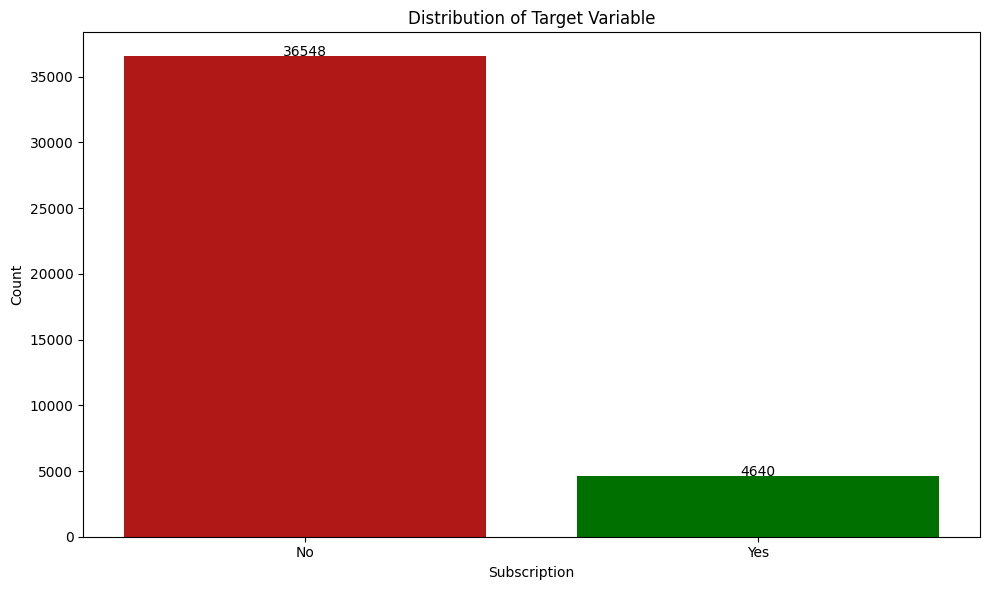

In [5]:
plt.figure(figsize=(10, 6))

y_unique, y_counts = np.unique(y, return_counts=True)

colors = ['#b01717', '#007000']
bars = plt.bar(["No", "Yes"], y_counts, color=colors)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.1, 
             str(int(height)), ha='center')

plt.title('Distribution of Target Variable')
plt.xlabel('Subscription')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

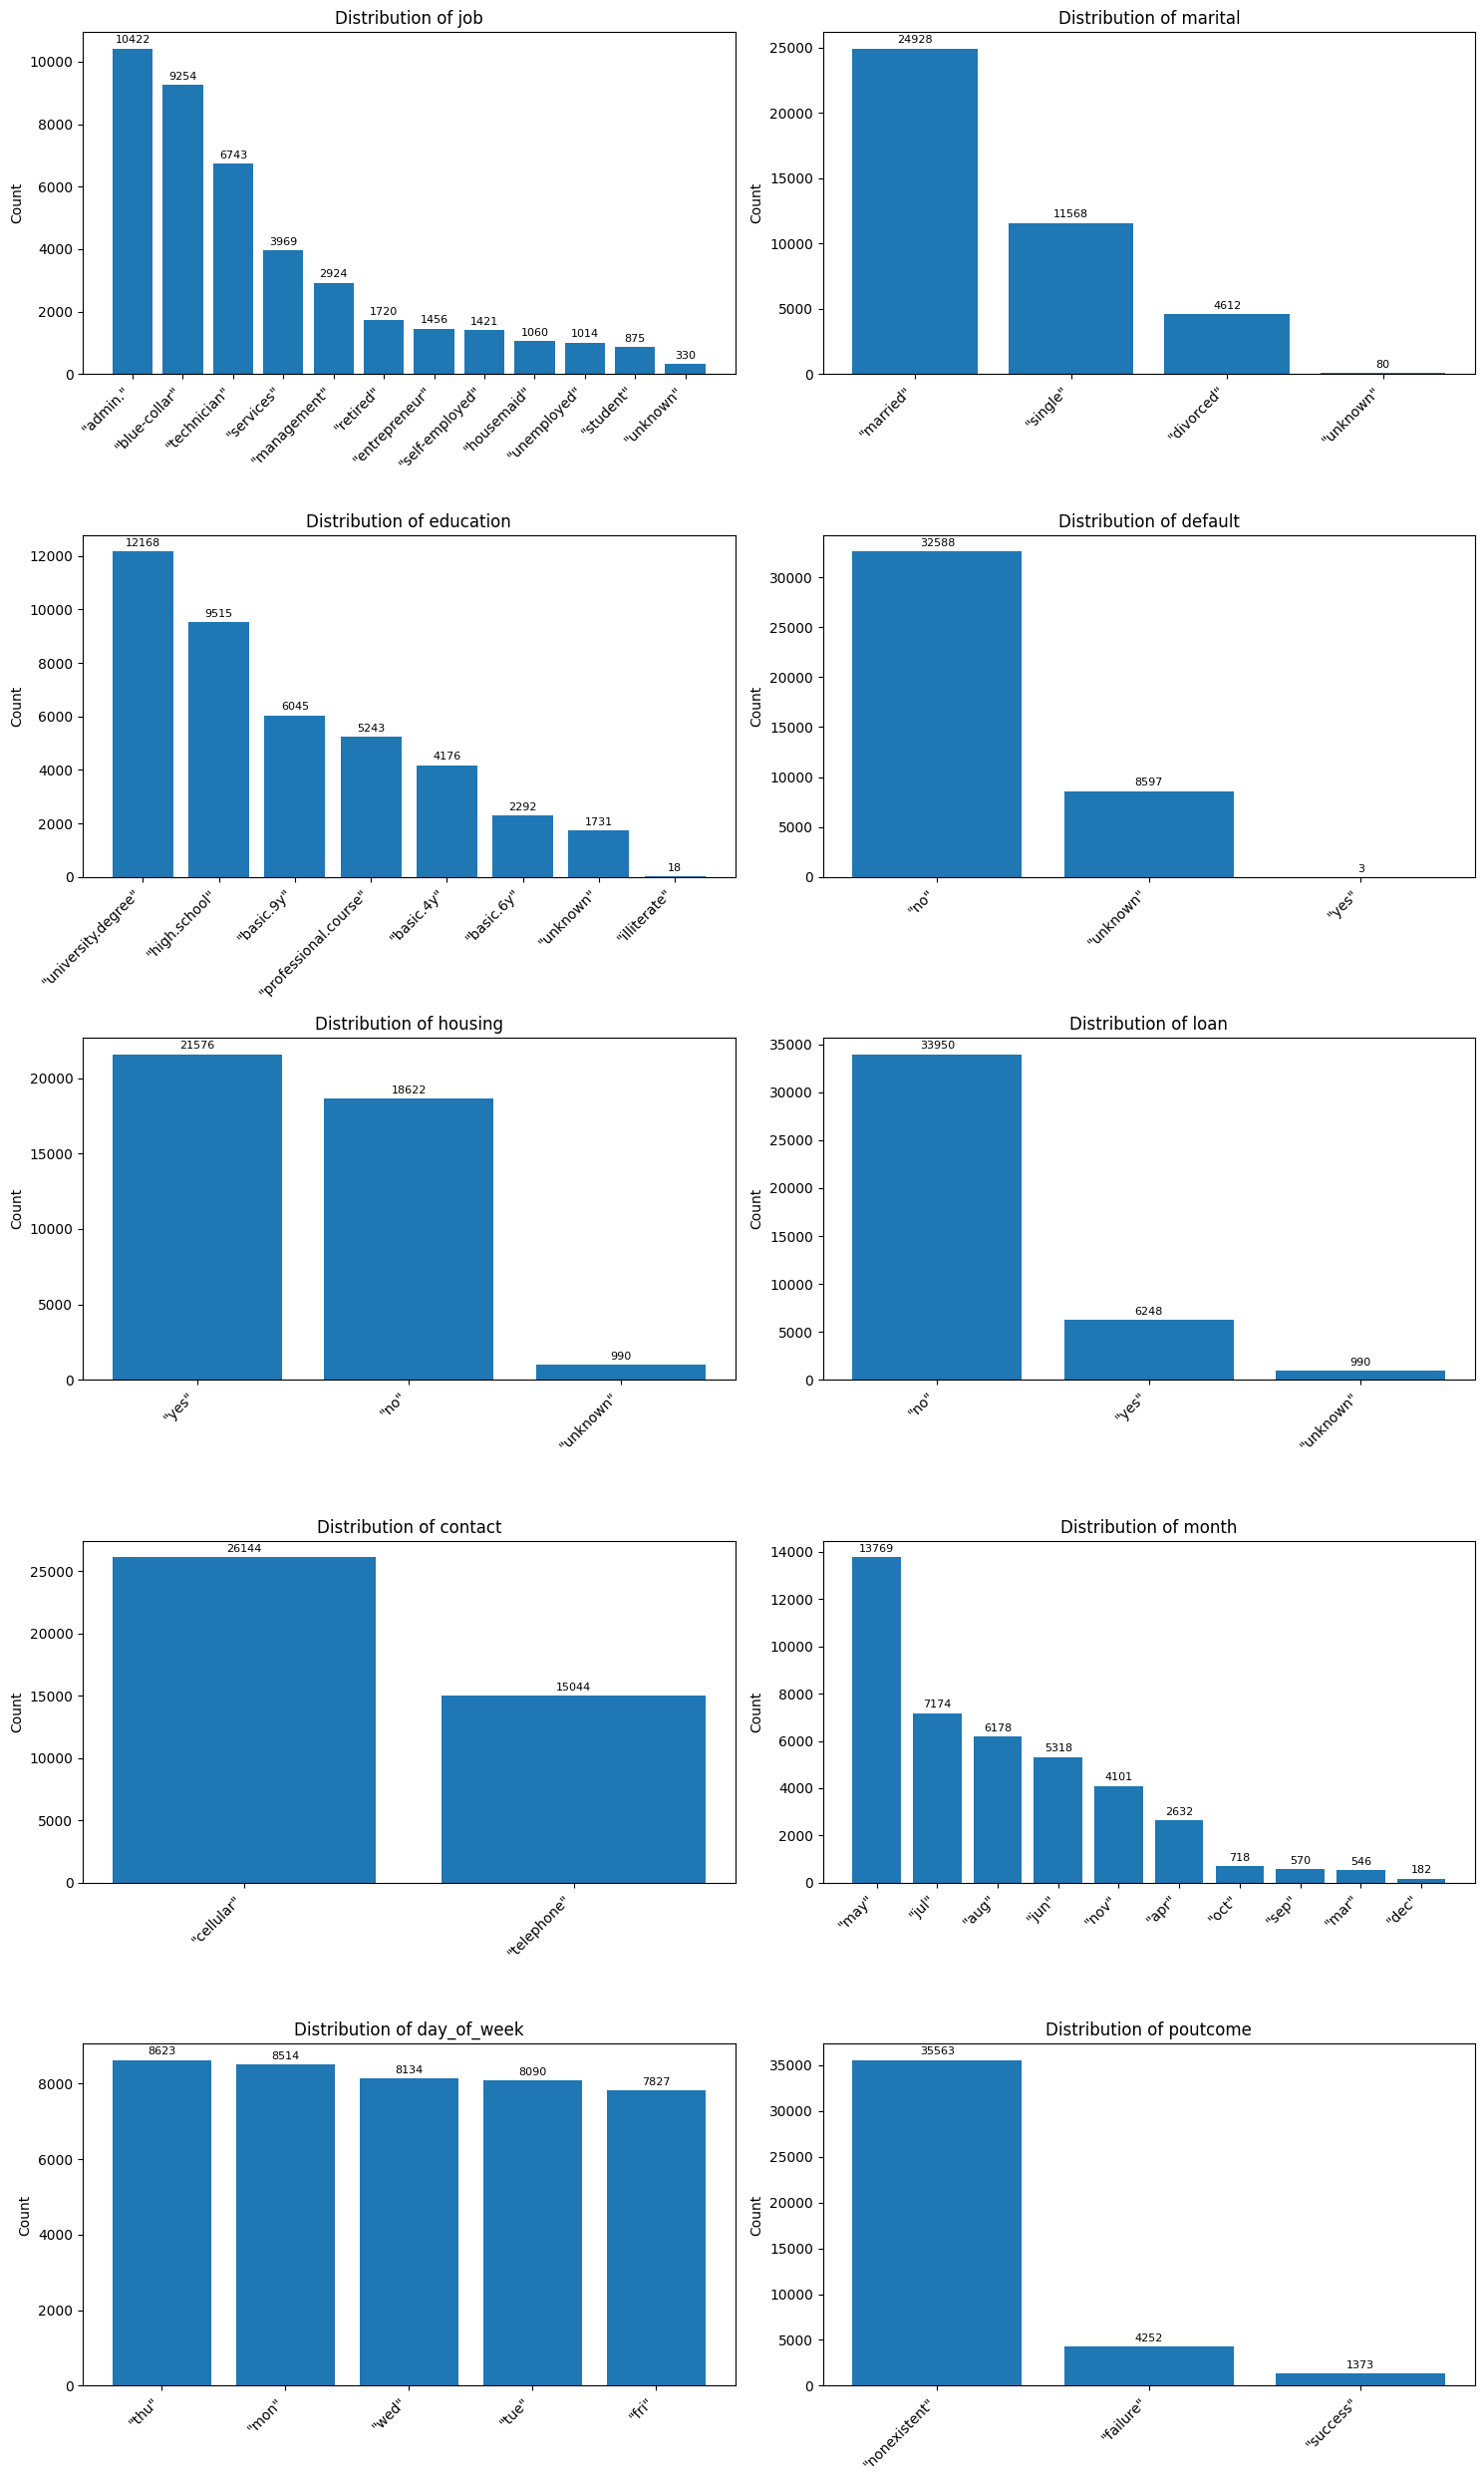

In [6]:
n_cols = 2
n_rows = int(np.ceil(len(categorical_cols_idx) / n_cols))

plt.figure(figsize=(15, 5 * n_rows))

for i, idx in enumerate(categorical_cols_idx):
    plt.subplot(n_rows, n_cols, i + 1)
    
    unique_categories, category_counts = np.unique(X[:, idx], return_counts=True)
    
    sort_indices = np.argsort(-category_counts)
    sorted_categories = unique_categories[sort_indices]
    sorted_counts = category_counts[sort_indices]
    
    bars = plt.bar(range(len(sorted_categories)), sorted_counts)
    
    for j, (bar, count) in enumerate(zip(bars, sorted_counts)):
        plt.text(bar.get_x() + bar.get_width()/2, count + 0.01*max(sorted_counts), str(int(count)), ha='center', va='bottom', fontsize=8)
    
    plt.title(f'Distribution of {header[idx]}')
    plt.ylabel('Count')
    plt.xticks(range(len(sorted_categories)), sorted_categories, rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Task 2 (Mandatory): Train a decision tree using scikit-learn.

Use max depth = 4 for initial interpretability. Visualize the tree using plot_tree().

**Discuss:** Which features are used at the top levels of the tree? Are they intuitive? 

---

Top level features:
- nr.employes (Level 1)
    - It shows how many people are employed in the economy.
    - Makes sense, as when more people have jobs they might feel more secure and less interested in long-term deposits.
- duration (Level 2 & 3)
    - This shows how long the last phone call with the client lasted.
    - Makes sense, as longer calls usually mean the person was interested and talked more, which can lead to a subscription.
- cons.conf.index (Level 3)
    - Consumer confidence shows how positive people feel about the economy.
    - Makes sense, as lower confidence might reduce willingness to invest.
- pdays (Level 3)
    - It shows number of days since last contact
    - Makes sense, as if people were contacted recently, they're more likely to subscribe, while if a long time passed, they might be less interested.

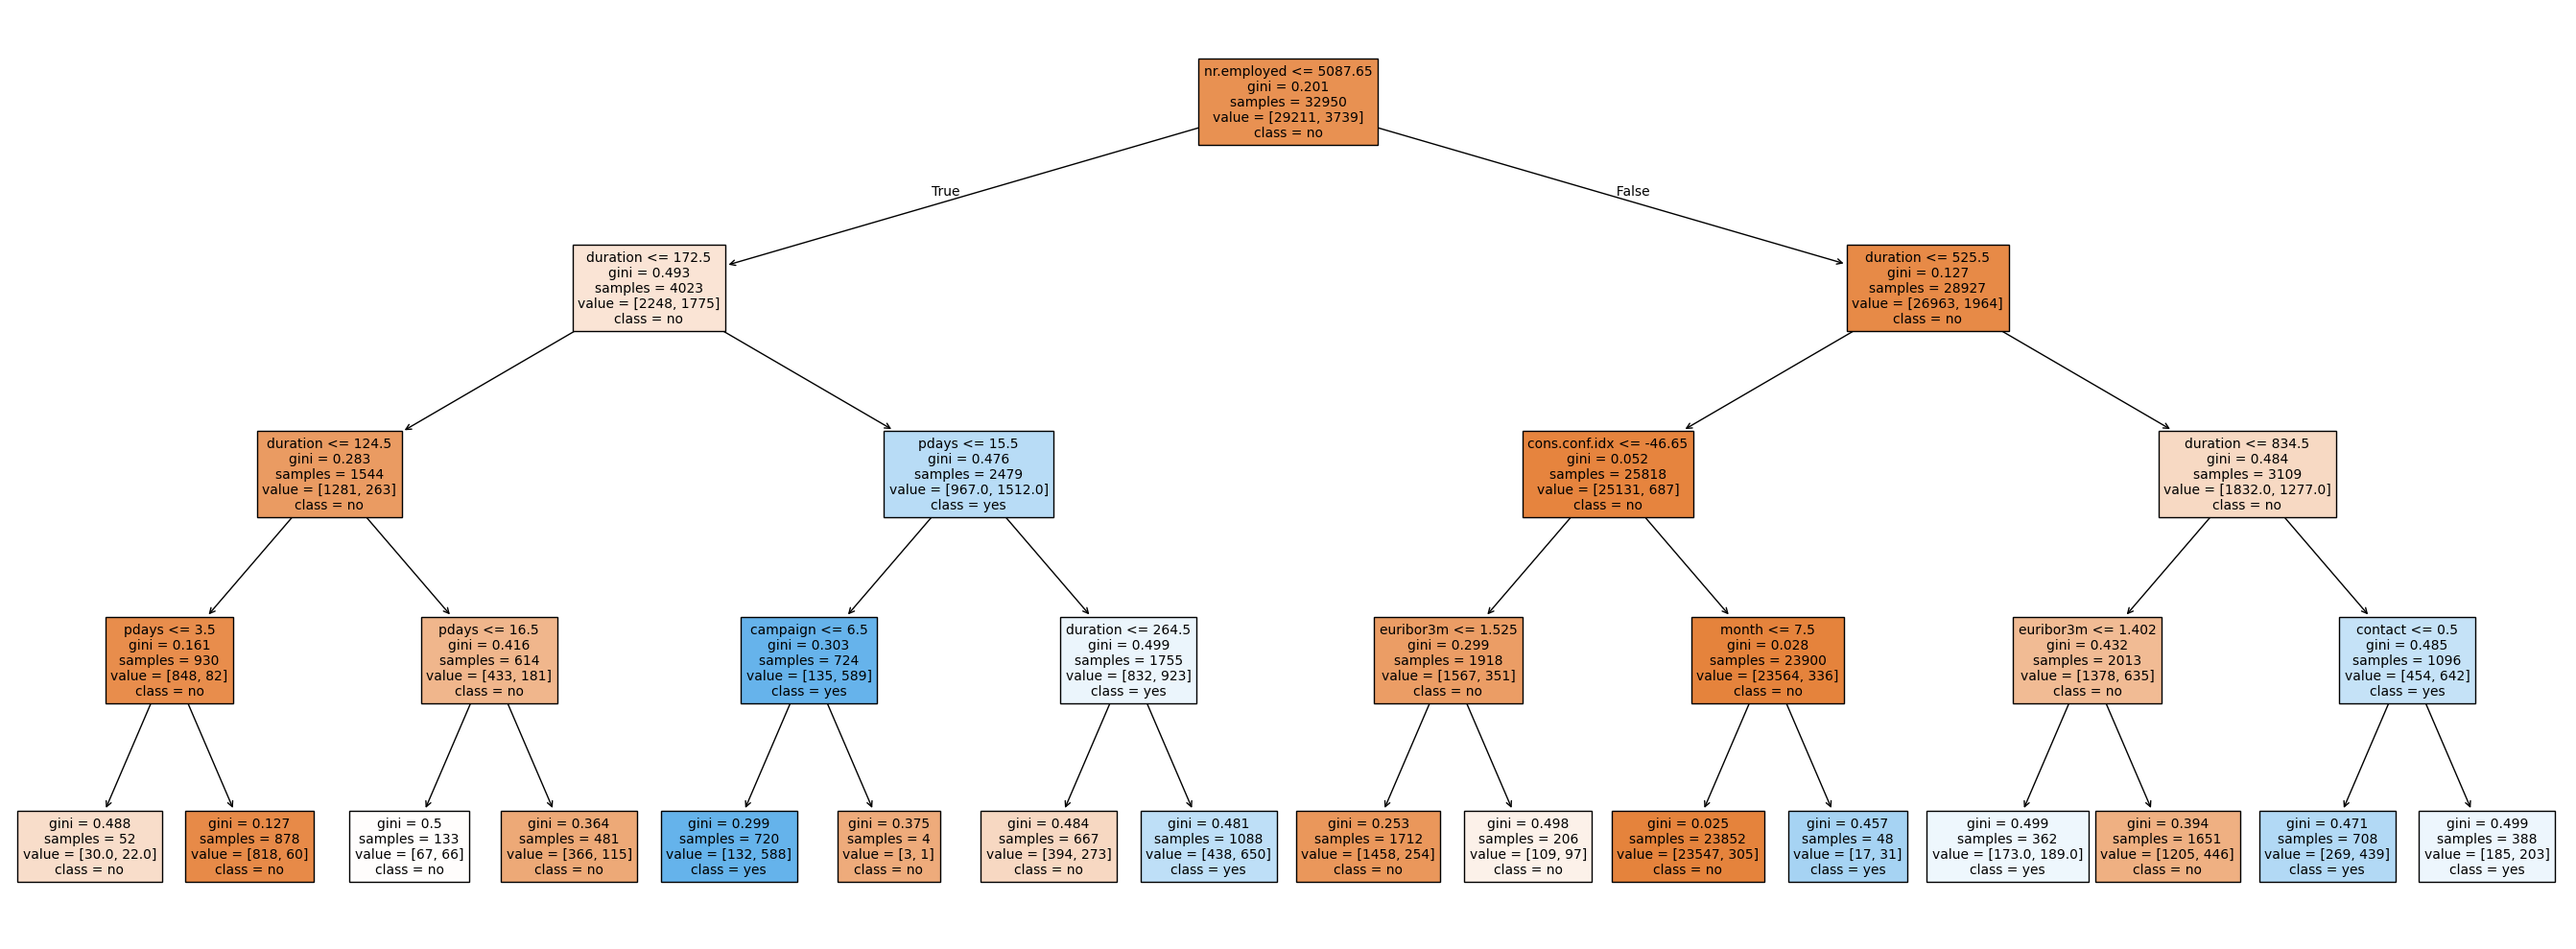

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

clf = DecisionTreeClassifier(max_depth=4, random_state=65)
clf.fit(X_train, y_train)

plt.figure(figsize=(27, 10))
plot_tree(clf, filled=True, feature_names=header, class_names=unique_y.astype(str), fontsize=10)
plt.tight_layout()
plt.show()

### Task 3 (mandatory): Evaluate Performance and Overfitting
Train the same tree with increasing depths (e.g., 2 to 10). Evaluate on both training and test sets using accuracy and F1 score. Plot Accuracy vs. depth and F1 vs. depth.

**Discuss:** Is there overfitting? Where does performance peak?

--- 

Overfitting happens as the tree depth increases, and we can see this in the accuracy and F1 score plots:
- Training accuracy keeps going up from depth 2 to 15, reaching over 97% at the deepest level.
- But test accuracy stops improving after depth 5 and starts to drop, meaning the model is overfitting the training data and losing its ability to generalize.
- Similarly, train F1 score rises a lot, but test F1 score peaks at depth 4 and then goes down. This is important because the F1 score shows how well the model handles the minority class (subscribed clients).

Models performance base on the plot and the outputs:
- In the Accuracy plot:
    - Test Accuracy is highest at depth 5 (based on the output and plot).
    - After depth 5, there’s a clear gap between train and test accuracy.
    - Train accuracy keeps increasing, but test accuracy starts to drop, which is a sign of overfitting.

- In the F1 Score plot:
    - Test F1 score is highest at depth 4 and then slowly decreases.
    - This means the model is missing more true positives (real subscribers) as it becomes more complex.

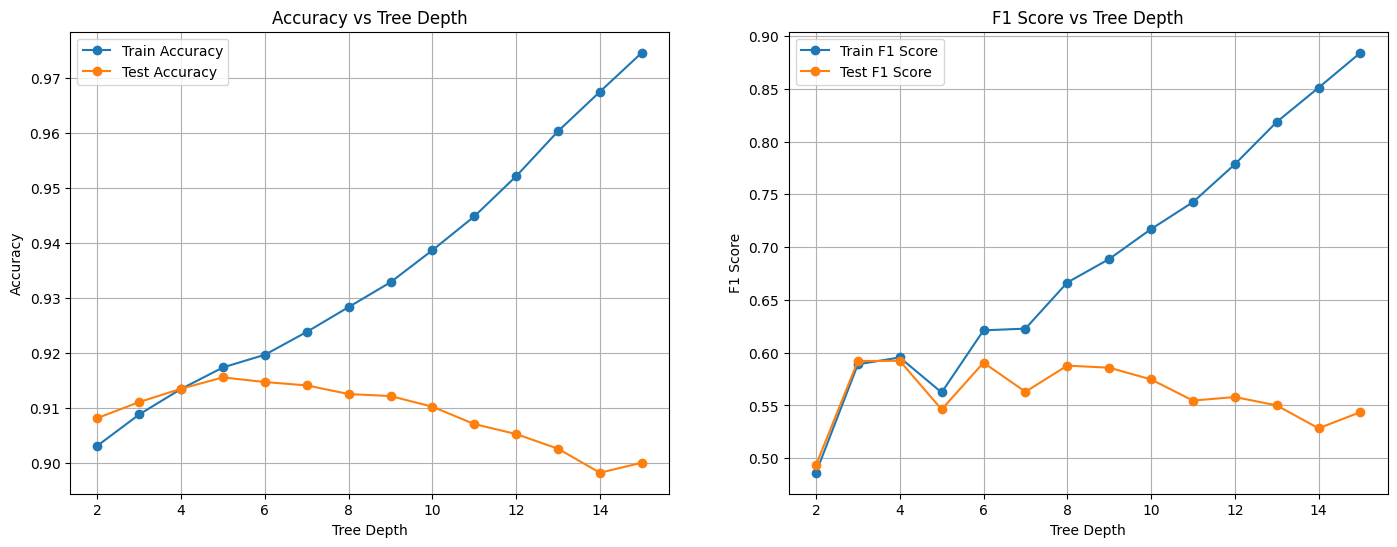

Best depth for test accuracy: 5
Best depth for test F1 score: 4


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

depths = range(2, 16)
train_accuracies = []
test_accuracies = []
train_f1_scores = []
test_f1_scores = []

for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=65)
    clf.fit(X_train, y_train)
    
    train_pred = clf.predict(X_train)
    test_pred = clf.predict(X_test)
    
    train_accuracies.append(accuracy_score(y_train, train_pred))
    test_accuracies.append(accuracy_score(y_test, test_pred))
    
    train_f1_scores.append(f1_score(y_train, train_pred))
    test_f1_scores.append(f1_score(y_test, test_pred))
    
plt.figure(figsize=(17, 6))

plt.subplot(1, 2, 1)
plt.plot(depths, train_accuracies, label='Train Accuracy', marker='o')
plt.plot(depths, test_accuracies, label='Test Accuracy', marker='o')
plt.xlabel('Tree Depth')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Tree Depth')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(depths, train_f1_scores, label='Train F1 Score', marker='o')
plt.plot(depths, test_f1_scores, label='Test F1 Score', marker='o')
plt.xlabel('Tree Depth')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Tree Depth')
plt.legend()
plt.grid()
plt.show()

best_accuracy_depth = depths[np.argmax(test_accuracies)]
best_f1_depth = depths[np.argmax(test_f1_scores)]

print(f"Best depth for test accuracy: {best_accuracy_depth}")
print(f"Best depth for test F1 score: {best_f1_depth}")

### Task 4 (Mandatory): Train and Compare Ensembles
Train a Random Forest and a Gradient Boosting model.
Tune hyperparameters using grid search (e.g., max_depth, n_estimators).
Do a plot comparing the ROC curves of the three models (Tree, RF, GB).

**Discuss:** Which model performs best and why?

----

Performance Ranking:
- Gradient Boosting (AUC = 0.9515): Best performer
- Random Forest (AUC = 0.9477): Close second  
- Decision Tree (AUC = 0.9281): Lowest performance

Why Gradient Boosting is the best:
- Gradient Boosting got the highest AUC because it builds models step by step, with each new tree fixing the mistakes of the previous ones. This makes it really good at finding complex patterns and handling tricky cases that simpler models can’t catch.
- The best parameters (learning_rate=0.2, max_depth=3, n_estimators=100) show that it used a balance of complexity and enough iterations to learn well without overfitting.

How Random Forest performed:
- Random Forest was very close (only 0.004 less in AUC) because it combines a lot of different trees and reduces overfitting by averaging their results. 
- Its best parameters (max_depth=10, n_estimators=50) show it used deeper trees but fewer of them.

Why Decision Tree didn’t do as well:
- The single decision tree, even with the best depth=5, doesn’t have the power of ensembles to handle complex patterns or edge cases in the data.

All three models performed better than random guessing (above the diagonal), but Gradient Boosting and Random Forest curves are closer to the top-left corner. This means they have better true positive rates with lower false positive rates, which is super important for this imbalanced dataset where finding the minority class (subscribers) matters the most.


Best RF parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}
Best RF accuracy score: 0.9150

Best GB parameters: {'learning_rate': 0.2, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100}
Best GB accuracy score: 0.9181

ROC AUC Scores:
Decision Tree AUC: 0.9281
Random Forest AUC: 0.9477
Gradient Boosting AUC: 0.9515


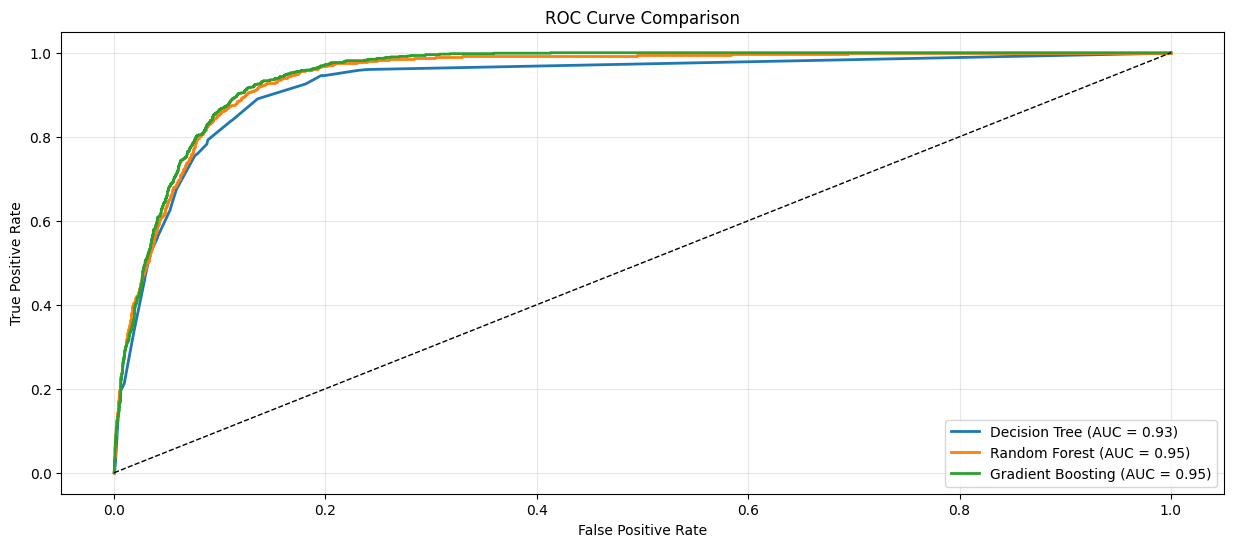

In [9]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc, RocCurveDisplay

dt = DecisionTreeClassifier(max_depth = 5, random_state=65)
dt.fit(X_train, y_train)

rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=65), rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)

rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_

print(f"Best RF parameters: {rf_grid.best_params_}")
print(f"Best RF accuracy score: {rf_grid.best_score_:.4f}\n")

gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'min_samples_split': [2, 5]
}

gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=65), gb_param_grid, cv=5, scoring='accuracy', n_jobs=-1)

gb_grid.fit(X_train, y_train)
gb_best = gb_grid.best_estimator_
print(f"Best GB parameters: {gb_grid.best_params_}")
print(f"Best GB accuracy score: {gb_grid.best_score_:.4f}\n")

plt.figure(figsize=(15, 6))

dt_probs = dt.predict_proba(X_test)[:, 1]
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_probs)
dt_auc = auc(dt_fpr, dt_tpr)
plt.plot(dt_fpr, dt_tpr, label=f'Decision Tree (AUC = {dt_auc:.2f})', lw=2)

rf_probs = rf_best.predict_proba(X_test)[:, 1]
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
rf_auc = auc(rf_fpr, rf_tpr)
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.2f})', lw=2)

gb_probs = gb_best.predict_proba(X_test)[:, 1]
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_probs)
gb_auc = auc(gb_fpr, gb_tpr)
plt.plot(gb_fpr, gb_tpr, label=f'Gradient Boosting (AUC = {gb_auc:.2f})', lw=2)

print("ROC AUC Scores:")
print(f"Decision Tree AUC: {dt_auc:.4f}")
print(f"Random Forest AUC: {rf_auc:.4f}")
print(f"Gradient Boosting AUC: {gb_auc:.4f}")

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

### Task 5 (Non-Mandatory): Feature Importance Analysis

Extract and plot feature importances for the ensemble models.

Plot the top 10 features by importance (bar chart).

**Discuss:** Are these the same features that dominated the decision tree?

---

Both ensemble models agree with the decision tree on the top 3 most important features, though in slightly different order:
- duration: Dominates all models
- nr.employed: High importance across all models
- euribor3m: Consistently in top 3-5

Key Differences:

The decision tree concentrated 50.7% of importance in duration alone, while ensemble methods spread this more evenly (37.8%-47.1%). Random Forest prioritizes euribor3m over nr.employed, while Gradient Boosting maintains the decision tree's ranking but with more balanced weights.

The ensemble models also identify previously overlooked features. Poutcome jumps into the top 5-6 positions for both ensembles despite not appearing in the decision tree's top 10. Age similarly gains prominence, especially in Random Forest.

Why These Differences Matter:

Decision trees make hierarchical splits that naturally concentrate importance in fewer features. Ensemble methods combine multiple perspectives, revealing additional relationships that single trees miss. Random Forest's random sampling discovers value in economic indicators like euribor3m, while Gradient Boosting's sequential learning maintains core patterns but distributes importance more fairly.

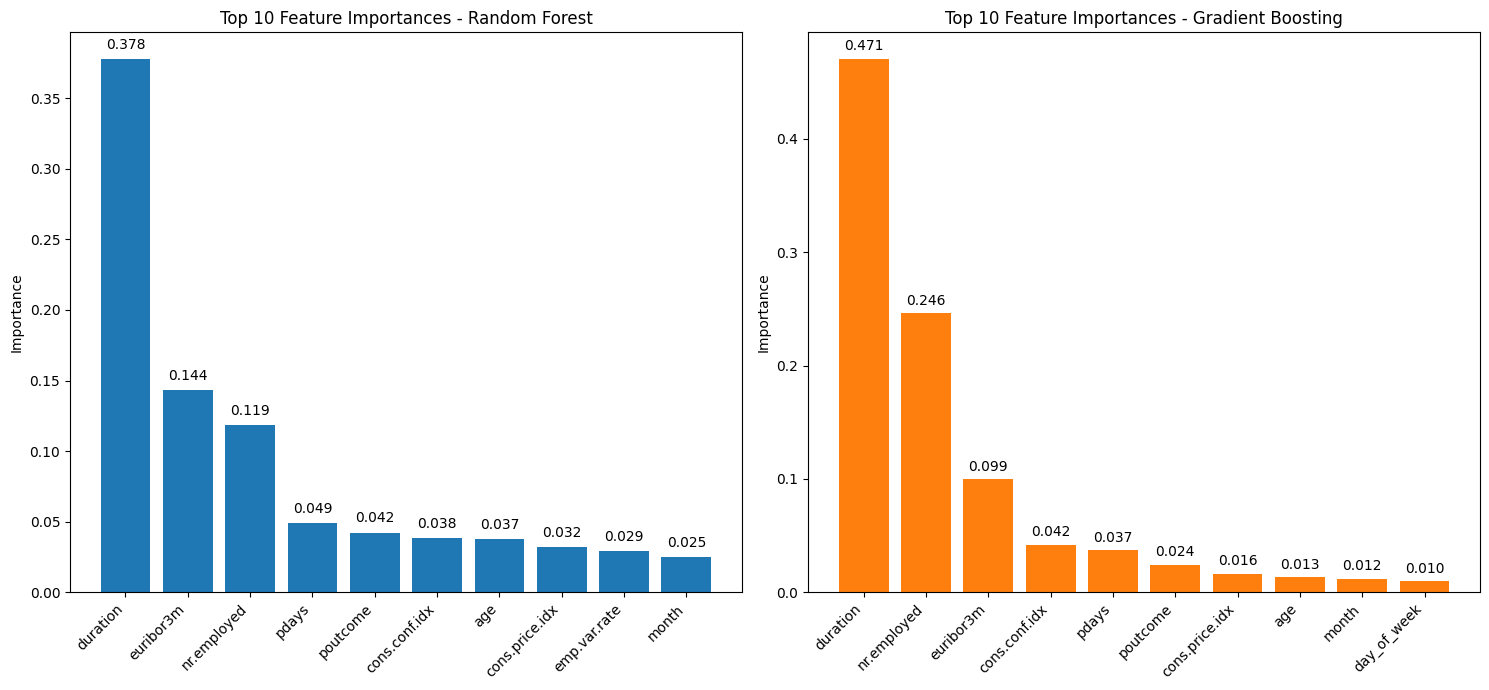

Top 10 features comparison:
--------------------------------------------------------------------------------
Rank  Decision Tree             Random Forest             Gradient Boosting        
--------------------------------------------------------------------------------
1.    duration (0.507)          duration (0.378)          duration (0.471)         
2.    nr.employed (0.349)       euribor3m (0.144)         nr.employed (0.246)      
3.    pdays (0.039)             nr.employed (0.119)       euribor3m (0.099)        
4.    cons.conf.idx (0.036)     pdays (0.049)             cons.conf.idx (0.042)    
5.    euribor3m (0.036)         poutcome (0.042)          pdays (0.037)            
6.    month (0.014)             cons.conf.idx (0.038)     poutcome (0.024)         
7.    day_of_week (0.009)       age (0.037)               cons.price.idx (0.016)   
8.    cons.price.idx (0.004)    cons.price.idx (0.032)    age (0.013)              
9.    contact (0.004)           emp.var.rate (0.029)  

In [10]:
dt_importances = dt.feature_importances_
rf_importances = rf_best.feature_importances_
gb_importances = gb_best.feature_importances_

dt_sorted_indices = np.argsort(dt_importances)[::-1]
dt_top10_indices = dt_sorted_indices[:10]
dt_top10_features = [header[i] for i in dt_top10_indices]
dt_top10_values = dt_importances[dt_top10_indices]

rf_sorted_indices = np.argsort(rf_importances)[::-1]
rf_top10_indices = rf_sorted_indices[:10]
rf_top10_features = [header[i] for i in rf_top10_indices]
rf_top10_values = rf_importances[rf_top10_indices]

gb_sorted_indices = np.argsort(gb_importances)[::-1]
gb_top10_indices = gb_sorted_indices[:10]
gb_top10_features = [header[i] for i in gb_top10_indices]
gb_top10_values = gb_importances[gb_top10_indices]

plt.figure(figsize=(15, 7))

plt.subplot(1, 2, 1)
x_pos = np.arange(10)
bars = plt.bar(x_pos, rf_top10_values, color='tab:blue')
plt.xticks(x_pos, rf_top10_features, rotation=45, ha='right')
plt.ylabel('Importance')
plt.title('Top 10 Feature Importances - Random Forest')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.005, f'{height:.3f}', ha='center', va='bottom')
    
plt.subplot(1, 2, 2)
bars = plt.bar(x_pos, gb_top10_values, color='tab:orange')
plt.xticks(x_pos, gb_top10_features, rotation=45, ha='right')
plt.ylabel('Importance')
plt.title('Top 10 Feature Importances - Gradient Boosting')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.005, f'{height:.3f}', ha='center', va='bottom')
    
plt.tight_layout()
plt.show()

print("Top 10 features comparison:")
print("-" * 80)
print(f"{'Rank':<5} {'Decision Tree':<25} {'Random Forest':<25} {'Gradient Boosting':<25}")
print("-" * 80)
for i in range(10):
    rank = f"{i+1}."
    dt_feature = f"{dt_top10_features[i]} ({dt_top10_values[i]:.3f})"
    rf_feature = f"{rf_top10_features[i]} ({rf_top10_values[i]:.3f})"
    gb_feature = f"{gb_top10_features[i]} ({gb_top10_values[i]:.3f})"
    print(f"{rank:<5} {dt_feature:<25} {rf_feature:<25} {gb_feature:<25}")
print("-" * 80)

### Task 6 (Non-Mandatory): Test Model Robustness to Noisy Features

Add synthetic noise features to the dataset. 
Generate 5–10 random columns with values sampled from a uniform or normal distribution.
Concatenate them with the original feature set.
Retrain your Random Forest and Gradient Boosting with the noisy features included.
Evaluate their performance on the test set.

Create a Bar plot comparing test set accuracy or F1 score before adding noise and after adding noise. 

**Discuss:** Did model performance degrade? Why or why not?

What does this tell you about the model’s ability to ignore irrelevant features?

Would feature selection or regularization help in this case?

---

When adding 7 synthetic noise features to the dataset, both models showed impressive resilience. Random Forest maintained exactly the same accuracy (0.9176), while Gradient Boosting dropped only slightly from 0.9192 to 0.9176. This minimal performance degradation suggests both algorithms have strong built-in feature selection capabilities.

However, the models handled noise differently. Random Forest gave 13.95% total importance to the noise features and even ranked one noise feature in its top 10. Gradient Boosting was much better at ignoring irrelevant information, assigning only 3.04% importance to noise features. This makes sense because Gradient Boosting learns sequentially and focuses on correcting previous mistakes, while Random Forest randomly samples features and might accidentally give weight to irrelevant ones.

The reason performance didn't crash is that tree-based algorithms naturally perform feature selection through their splitting process, they choose features that actually help separate the classes. The ensemble aspect also helps average out any bad decisions made on noise features.

This shows that feature selection would be valuable, especially for Random Forest which wasted nearly 14% of its attention on meaningless features. In real-world scenarios with more noise or smaller datasets, this could hurt performance more significantly. Regularization techniques could also help prevent overfitting to irrelevant features, though both models already showed good natural resistance to noise in this case.

------------------------------------------------------------
Performance comparison:
------------------------------------------------------------
Random Forest original accuracy: 0.9176
Random Forest with noise accuracy: 0.9176
Accuracy change: 0.0000

Gradient Boosting original accuracy: 0.9192
Gradient Boosting with noise accuracy: 0.9176
Accuracy change: -0.0016
------------------------------------------------------------


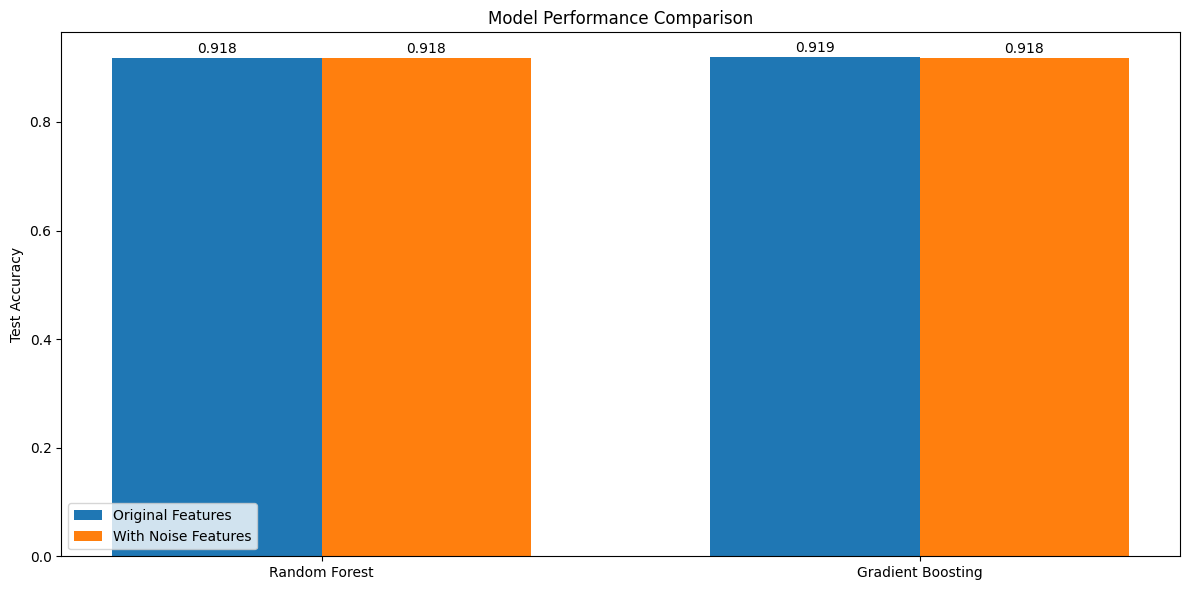

Noise feature analysis:
------------------------------------------------------------
Random Forest: 1/10 noise features in top 10, total importance: 13.95%
Gradient Boosting: 1/10 noise features in top 10, total importance: 3.04%

------------------------------------------------------------
Random Forest Top 10 Features with Noise:
------------------------------------------------------------
1. duration: 0.3421
2. euribor3m: 0.1254
3. nr.employed: 0.1166
4. poutcome: 0.0519
5. emp.var.rate: 0.0311
6. cons.conf.idx: 0.0304
7. pdays: 0.0283
8. cons.price.idx: 0.0268
9. month: 0.0230
10. noise_3: 0.0215 (NOISE)
------------------------------------------------------------

------------------------------------------------------------
Gradient Boosting Top 10 Features with Noise:
------------------------------------------------------------
1. duration: 0.4600
2. nr.employed: 0.2431
3. euribor3m: 0.0964
4. cons.conf.idx: 0.0415
5. pdays: 0.0358
6. poutcome: 0.0227
7. cons.price.idx: 0.0167
8.

In [11]:
original_rf_pred = rf_best.predict(X_test)
original_rf_accuracy = accuracy_score(y_test, original_rf_pred)
original_rf_f1 = f1_score(y_test, original_rf_pred)

original_gb_pred = gb_best.predict(X_test)
original_gb_accuracy = accuracy_score(y_test, original_gb_pred)
original_gb_f1 = f1_score(y_test, original_gb_pred)

np.random.seed(65)
n_noise_features = 7

n_samples = X_train.shape[0]
noise_train = np.zeros((n_samples, n_noise_features))
for i in range(n_noise_features):
    if i % 2 == 0:
        noise_train[:, i] = np.random.uniform(0, 1, n_samples)
    else:
        noise_train[:, i] = np.random.normal(0, 1, n_samples)
        
n_test_samples = X_test.shape[0]
noise_test = np.zeros((n_test_samples, n_noise_features))
for i in range(n_noise_features):
    if i % 2 == 0:
        noise_test[:, i] = np.random.uniform(0, 1, n_test_samples)
    else:
        noise_test[:, i] = np.random.normal(0, 1, n_test_samples)
        
X_train_noisy = np.column_stack([X_train, noise_train])
X_test_noisy = np.column_stack([X_test, noise_test])

noise_feature_names = [f"noise_{i+1}" for i in range(n_noise_features)]
header_noisy = np.concatenate((header, noise_feature_names))

rf_noisy = RandomForestClassifier(random_state=65, **rf_grid.best_params_)
rf_noisy.fit(X_train_noisy, y_train)

noisy_rf_pred = rf_noisy.predict(X_test_noisy)
noisy_rf_accuracy = accuracy_score(y_test, noisy_rf_pred)
noisy_rf_f1 = f1_score(y_test, noisy_rf_pred)

gb_noisy = GradientBoostingClassifier(random_state=65, **gb_grid.best_params_)
gb_noisy.fit(X_train_noisy, y_train)

noisy_gb_pred = gb_noisy.predict(X_test_noisy)
noisy_gb_accuracy = accuracy_score(y_test, noisy_gb_pred)
noisy_gb_f1 = f1_score(y_test, noisy_gb_pred)

noisy_gd_pred = gb_noisy.predict(X_test_noisy)
noisy_gb_accuracy = accuracy_score(y_test, noisy_gd_pred)
noisy_gb_f1 = f1_score(y_test, noisy_gd_pred)

print("-" * 60)
print("Performance comparison:")
print("-" * 60)
print(f"Random Forest original accuracy: {original_rf_accuracy:.4f}")
print(f"Random Forest with noise accuracy: {noisy_rf_accuracy:.4f}")
print(f"Accuracy change: {noisy_rf_accuracy - original_rf_accuracy:.4f}\n")
print(f"Gradient Boosting original accuracy: {original_gb_accuracy:.4f}")
print(f"Gradient Boosting with noise accuracy: {noisy_gb_accuracy:.4f}")
print(f"Accuracy change: {noisy_gb_accuracy - original_gb_accuracy:.4f}")
print("-" * 60)

plt.figure(figsize=(12, 6))

models = ['Random Forest', 'Gradient Boosting']
x = np.arange(len(models))
width = 0.35

plt.bar(x - width/2, [original_rf_accuracy, original_gb_accuracy], width, label='Original Features', color='tab:blue')
plt.bar(x + width/2, [noisy_rf_accuracy, noisy_gb_accuracy], width, label='With Noise Features', color='tab:orange')

for i, v in enumerate([original_rf_accuracy, original_gb_accuracy]):
    plt.text(i - width/2, v + 0.01, f'{v:.3f}', ha='center')
for i, v in enumerate([noisy_rf_accuracy, noisy_gb_accuracy]):
    plt.text(i + width/2, v + 0.01, f'{v:.3f}', ha='center')
    
plt.ylabel('Test Accuracy')
plt.title('Model Performance Comparison')
plt.xticks(x, models)
plt.legend()
plt.tight_layout()
plt.show()

rf_noisy_importances = rf_noisy.feature_importances_
rf_noisy_sorted_indices = np.argsort(rf_noisy_importances)[::-1]
rf_noisy_top10_indices = rf_noisy_sorted_indices[:10]

gb_noisy_importances = gb_noisy.feature_importances_
gb_noisy_sorted_indices = np.argsort(gb_noisy_importances)[::-1]
gb_noisy_top10_indices = gb_noisy_sorted_indices[:10]

rf_noise_count = sum(1 for idx in rf_noisy_top10_indices if "noise" in header_noisy[idx])
gb_noise_count = sum(1 for idx in gb_noisy_top10_indices if "noise" in header_noisy[idx])
rf_noise_importance = sum(rf_noisy_importances[i] for i in range(len(header_noisy)) if "noise" in header_noisy[i])
gb_noise_importance = sum(gb_noisy_importances[i] for i in range(len(header_noisy)) if "noise" in header_noisy[i])

print("Noise feature analysis:")
print("-" * 60)
print(f"Random Forest: {rf_noise_count}/10 noise features in top 10, total importance: {rf_noise_importance*100:.2f}%")
print(f"Gradient Boosting: {gb_noise_count}/10 noise features in top 10, total importance: {gb_noise_importance*100:.2f}%")

print()
print("-" * 60)
print("Random Forest Top 10 Features with Noise:")
print("-" * 60)
for i, idx in enumerate(rf_noisy_top10_indices):
    feature_name = header_noisy[idx]
    importance = rf_noisy_importances[idx]
    print(f"{i+1}. {feature_name}: {importance:.4f}" + (" (NOISE)" if "noise" in feature_name else ""))
print("-" * 60)
 
print()
print("-" * 60)
print("Gradient Boosting Top 10 Features with Noise:")
print("-" * 60)
for i, idx in enumerate(gb_noisy_top10_indices):
    feature_name = header_noisy[idx]
    importance = gb_noisy_importances[idx]
    print(f"{i+1}. {feature_name}: {importance:.4f}" + (" (NOISE)" if "noise" in feature_name else ""))
print("-" * 60)

## Lecture 7 - Kernels, Maximal Margin Classifiers

### Task 1 (Mandatory): Data Exploration and Preprocessing

Load the dataset using sklearn.datasets.load_breast_cancer().

Standardize the features using StandardScaler.
Use pairplot or PCA to project to 2D and show class separation.

**Discuss:** Do the two classes appear linearly separable?
 
---

After applying PCA to the breast cancer dataset, the two classes (malignant and benign) show noticeable separation, but they are not perfectly linearly separable.

From the PCA plot, benign samples (blue) are mostly clustered on the negative side of Principal Component 1 (left side), while malignant samples (red) are more concentrated on the positive side (right side). This suggests that PC1 captures a significant amount of variance that helps distinguish between the two classes.

However, there is some overlap between the classes, especially near the center around PC1=0. This overlap indicates that a single straight line would not be able to perfectly separate the two classes in this 2D space. Additionally, some malignant samples are mixed within the benign cluster and vice versa.

The spread along Principal Component 2 does not seem to contribute much to class separation, as both classes have similar distributions along this axis.


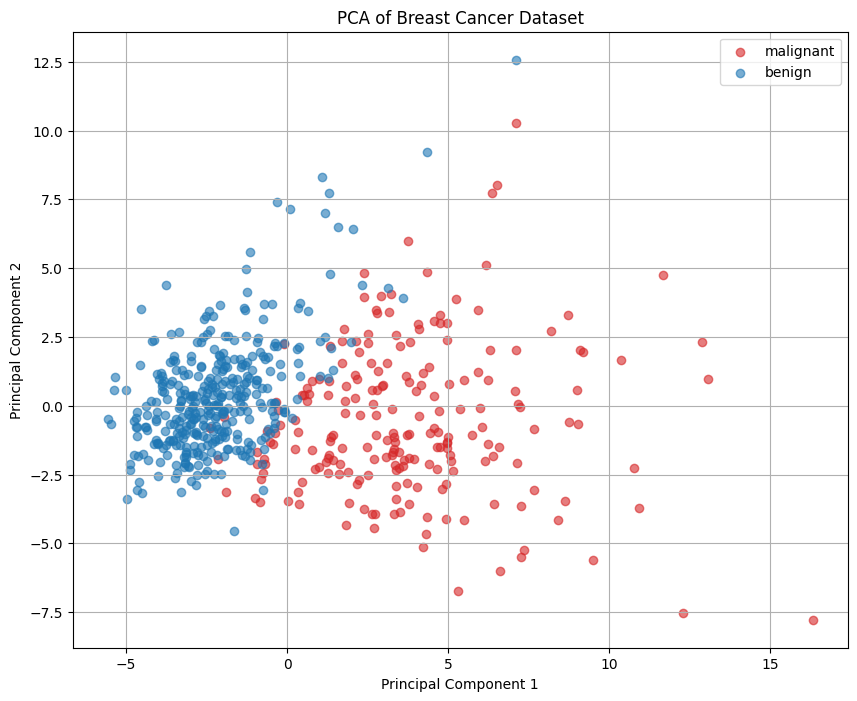

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

data = sklearn.datasets.load_breast_cancer()
X = data.data
y = data.target
target_names = data.target_names

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_pca_with_target = np.column_stack((X_pca, y))

class_0 = X_pca_with_target[X_pca_with_target[:, 2] == 0]
class_1 = X_pca_with_target[X_pca_with_target[:, 2] == 1]

plt.figure(figsize=(10, 8))
plt.scatter(class_0[:, 0], class_0[:, 1], color='tab:red', label=target_names[0], alpha=0.6)
plt.scatter(class_1[:, 0], class_1[:, 1], color='tab:blue', label=target_names[1], alpha=0.6)
plt.title('PCA of Breast Cancer Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid()
plt.show()

### Task 2 (Mandatory): Train Linear and RBF SVMs

Train two SVM classifiers: one with a linear kernel and one with an RBF kernel.

Use a fixed C=1.0, and for RBF, use default gamma='scale'.

Plot the confusion matrices or classification reports for both models.

**Discuss:** Which kernel performed better? Why might that be?

---

The linear SVM outperformed the RBF kernel SVM on this dataset, achieving 99.12% accuracy compared to 96.49%. 

Looking at the confusion matrices:
- Linear SVM made only 1 error (a benign sample misclassified as malignant)
- RBF SVM made 4 errors (2 in each direction)

Typically, RBF kernels are expected to handle more complex data better since they can create curved decision boundaries. But in this case, the simpler linear approach worked better. This suggests that despite the overlap seen in the PCA plot, the breast cancer data actually separates quite well with just a straight line when all 30 features are considered (not just the 2D projection).

For medical diagnostics, the Linear SVM's perfect sensitivity (no false negatives) is particularly valuable, as missing a malignant tumor (false negative) is generally considered more problematic than misclassifying a benign tumor. 

In this case, the linear decision boundary was sufficient and even optimal for separating the classes in the high-dimensional feature space.

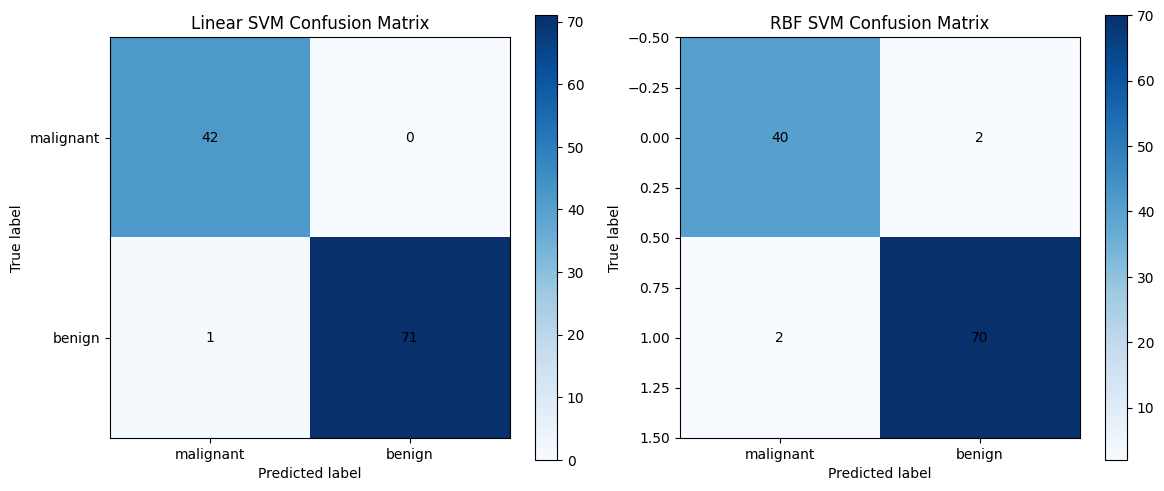

Linear SVM Accuracy: 0.9912
RBF SVM Accuracy: 0.9649


In [13]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=435)

svm_linear = SVC(kernel='linear', C=1.0, random_state=435)
svm_linear.fit(X_train, y_train)
y_pred_linear = svm_linear.predict(X_test)
cm_linear = confusion_matrix(y_test, y_pred_linear)

svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=435)
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
im1 = plt.imshow(cm_linear, interpolation='nearest', cmap='Blues')
plt.title('Linear SVM Confusion Matrix')
plt.colorbar(im1)
tick_marks = np.arange(len(data.target_names))
plt.xticks(tick_marks, data.target_names)
plt.yticks(tick_marks, data.target_names)
plt.xlabel('Predicted label')
plt.ylabel('True label')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_linear[i, j], ha='center', va='center')
        
plt.subplot(1, 2, 2)
im2 = plt.imshow(cm_rbf, interpolation='nearest', cmap='Blues')
plt.title('RBF SVM Confusion Matrix')
plt.colorbar(im2)
plt.xticks(tick_marks, data.target_names)
plt.xticks(tick_marks, data.target_names)
plt.xlabel('Predicted label')
plt.ylabel('True label')

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_rbf[i, j], ha='center', va='center')
        
plt.tight_layout()
plt.show()

linear_accuracy = svm_linear.score(X_test, y_test)
rbf_accuracy = svm_rbf.score(X_test, y_test)

print(f"Linear SVM Accuracy: {linear_accuracy:.4f}")
print(f"RBF SVM Accuracy: {rbf_accuracy:.4f}")

### Task 3 (Mandatory): Hyperparameter Tuning

Use grid search with cross-validation to find optimal values of C and gamma for the RBF kernel.

Plot a heatmap of validation accuracy or F1 score for the grid.

**Discuss:** What combination of hyperparameters gave the best results?

---

The grid search results reveal that the optimal hyperparameters for the RBF SVM on this breast cancer dataset are C=10 and gamma=0.01, achieving a cross-validation accuracy of 97.36%.

Looking at the heatmap patterns:

- Low C values (e.g. 0.001, 0.01) performed poorly, with an accuracy of only 62.64%, regardless of gamma. This suggests that the model requires some flexibility in regularization to fit the data properly. As C increases (from 0.1 to 10), performance improves significantly, indicating that higher C values allow the model to better capture the data's structure.
- Gamma parameter influence: Very high gamma values (1, 10) perform poorly across all C values, suggesting that too complex decision boundary overfits the data. The optimal value lies in the lower-middle range (0.001-0.1).
- Performance: Once the best settings are reached, performance slightly drops with very high C values, showing that reducing regularization further doesn't help much.


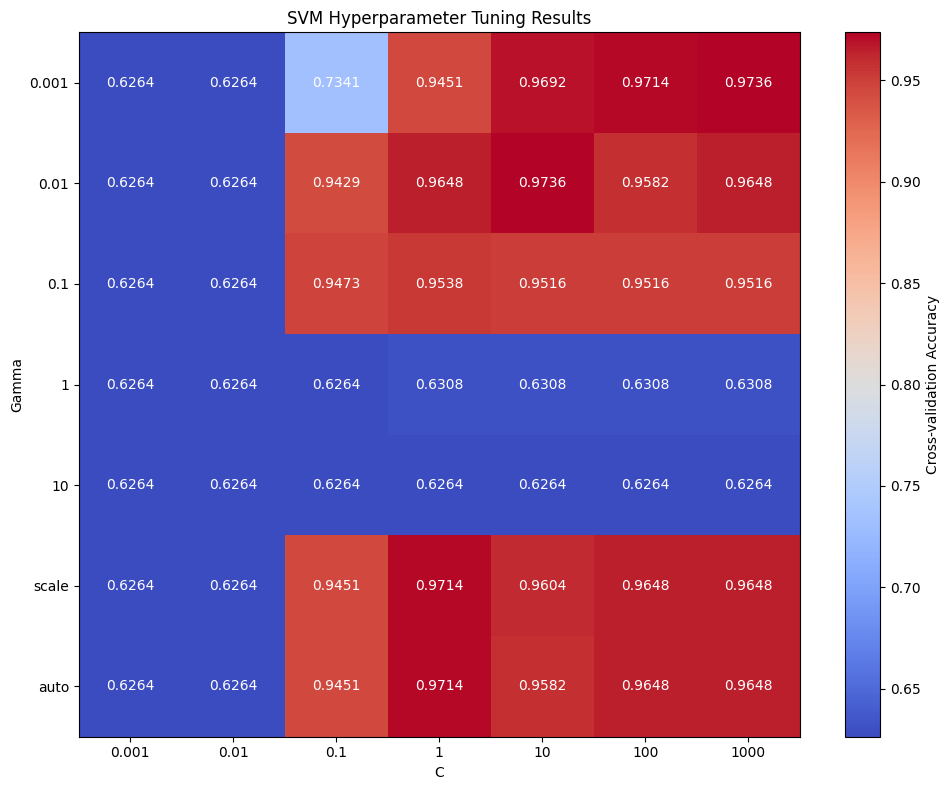

Best parameters: {'C': 10, 'gamma': 0.01}
Best cross-validation accuracy: 0.9736


In [14]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'gamma': [0.001, 0.01, 0.1, 1, 10, 'scale', 'auto']
}

svm_rbf_grid = SVC(kernel='rbf', random_state=865)
grid_search = GridSearchCV(svm_rbf_grid, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

results = grid_search.cv_results_
C_values = param_grid['C']
gamma_values = param_grid['gamma']

accuracy_matrix = np.zeros((len(gamma_values), len(C_values)))
for i, gamma in enumerate(gamma_values):
    for j, C in enumerate(C_values):
        for idx, params in enumerate(results['params']):
            if params['C'] == C and params['gamma'] == gamma:
                accuracy_matrix[i, j] = results['mean_test_score'][idx]
                break
            
plt.figure(figsize=(10, 8))
im = plt.imshow(accuracy_matrix, interpolation='nearest', cmap='coolwarm', aspect='auto')
plt.colorbar(im, label='Cross-validation Accuracy')
plt.title('SVM Hyperparameter Tuning Results')
plt.xlabel('C')
plt.ylabel('Gamma')

plt.xticks(np.arange(len(C_values)), C_values)
plt.yticks(np.arange(len(gamma_values)), gamma_values)

for i in range(len(gamma_values)):
    for j in range(len(C_values)):
        plt.text(j, i, f"{accuracy_matrix[i, j]:.4f}", ha='center', va='center', color='white')
        
plt.tight_layout()
plt.show()


print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")


### Task 4 (non-mandatory): Investigate the Effect of the Regularization Parameter C

Train RBF SVM models for a wide range of C values (e.g., 0.001, 0.01, 0.1, 1, 10, 100), keeping gamma fixed.

For each model, record training and test accuracy or F1 score.

Plot the training and test scores vs. C (line plot).

**Discuss:**

- What happens when C is very small or very large?

- What does this tell you about the role of C in the SVM objective?

---

The plot clearly illustrates the impact of the C parameter on SVM performance:

For very small C values (0.001-0.01):
- Both training and test accuracy remain low (~63%)
- The model is too regularized, creating a wide margin but misclassifying many points
- This demonstrates underfitting, the model is too simple to capture the underlying pattern

As C increases to moderate values (0.1-10):
- Performance improves dramatically on both training and test sets
- The C=10 is close to optimal balance (98.9% train, 98.25% test accuracy)
- The model finds appropriate flexibility to fit the data without overfitting

For very large C values (100-1000):
- Training accuracy continues growing, reaching 100% at C=1000
- Test accuracy declines (96.49% → 94.74%)
- The widening gap between training and test performance signals overfitting

This shows how important C is in SVMs. It balances between making the margin as wide as possible (regularization) and reducing classification errors. A small C focuses more on having a wide margin, even if it means lower accuracy. A large C, on the other hand, tries to fit the training data perfectly, which can hurt the model's ability to generalize to new data.

C=0.001, Train Accuracy: 0.6264, Test Accuracy: 0.6316
C=0.01, Train Accuracy: 0.6264, Test Accuracy: 0.6316
C=0.1, Train Accuracy: 0.9473, Test Accuracy: 0.9561
C=1, Train Accuracy: 0.9824, Test Accuracy: 0.9825
C=10, Train Accuracy: 0.9890, Test Accuracy: 0.9825
C=100, Train Accuracy: 0.9956, Test Accuracy: 0.9649
C=1000, Train Accuracy: 1.0000, Test Accuracy: 0.9474


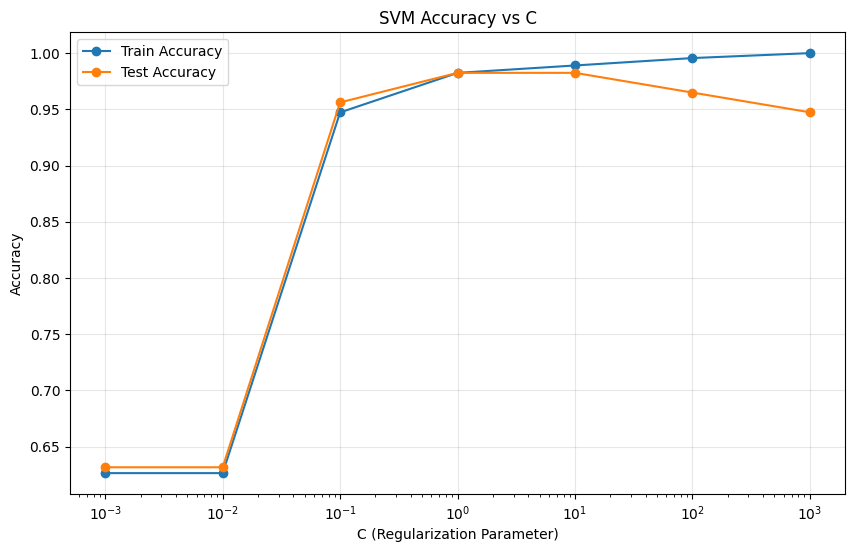

In [15]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
train_accuracies = []
test_accuracies = []

for C in C_values:
    svm_model = SVC(kernel='rbf', C=C, gamma=0.01, random_state=435)
    svm_model.fit(X_train, y_train)
    
    train_acc = svm_model.score(X_train, y_train)
    test_acc = svm_model.score(X_test, y_test)
    
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    
    print(f"C={C}, Train Accuracy: {train_acc:.4f}, Test Accuracy: {test_acc:.4f}")
    
plt.figure(figsize=(10, 6))
plt.plot(C_values, train_accuracies, label='Train Accuracy', marker='o')
plt.plot(C_values, test_accuracies, label='Test Accuracy', marker='o')
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Accuracy')
plt.title('SVM Accuracy vs C')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()    
    

### Task 5 (non-mandatory): Compare SVM with Logistic Regression

Train a logistic regression model on the same (standardized) data.

Compare its performance with your best-performing SVM.

Plot, side-by-side bar plot of accuracy, precision, recall, and F1 score for both models.

**Discuss:**

- Which model performed better overall?

- Were there significant differences in false positives or false negatives?

- Based on your task (e.g., cancer detection), which type of error is more costly?

---

Logistic Regression outperformed the best SVM model (RBF kernel, C=10, gamma=0.01) across most metrics:
- Accuracy: Logistic Regression achieved 99.12% vs SVM's 98.25%
- Precision: Logistic Regression reached perfect precision (1.0) compared to SVM's 0.9861
- Recall: Both models performed equally at 0.9861
- F1 Score: Logistic Regression's 0.9930 exceeded SVM's 0.9861

The confusion matrix shows an important distinction:
- Logistic Regression: 0 false positives, 1 false negative
- SVM: 1 false positive, 1 false negative

In breast cancer classification, false negatives are significantly more costly than false positives, as they could lead to delayed treatment and worse patient outcomes. Both models made one false negative error, making them equally concerning in this critical aspect. However, Logistic Regression avoided any false positives, giving it a slight advantage.

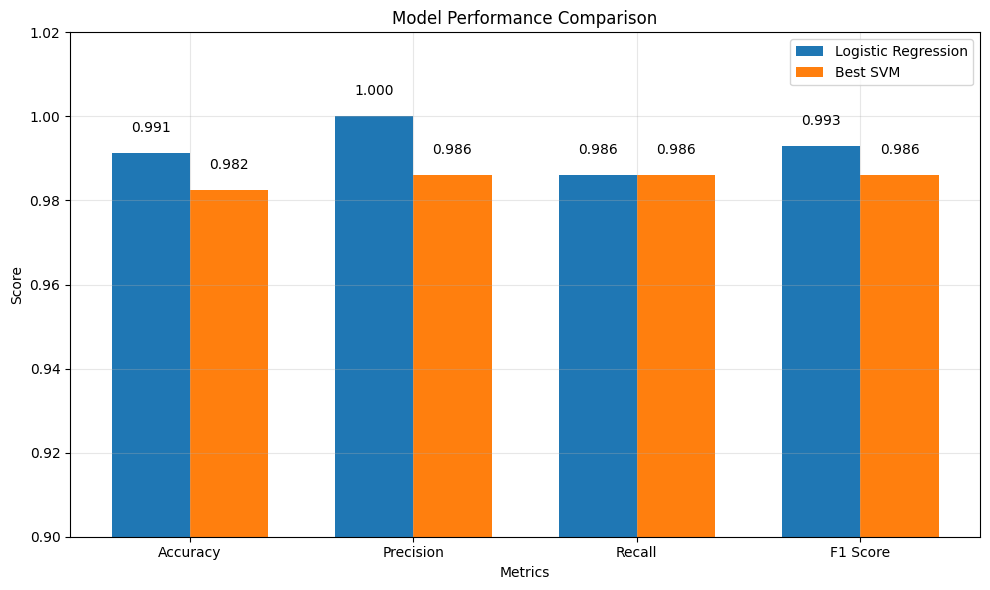

Model Performance Comparison:
------------------------------------------------------------
Accuracy  : LogReg=0.9912, SVM=0.9825
Precision : LogReg=1.0000, SVM=0.9861
Recall    : LogReg=0.9861, SVM=0.9861
F1 Score  : LogReg=0.9930, SVM=0.9861

Confusion Matrix Comparison:
------------------------------------------------------------
Logistic Regression - FP: 0, FN: 1
Best SVM - FP: 1, FN: 1


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

log_reg = LogisticRegression(max_iter=1000, random_state=435)
log_reg.fit(X_train, y_train)
y_pred_log_reg = log_reg.predict(X_test)

best_svm = SVC(kernel='rbf', C=10, gamma=0.01, random_state=435)
best_svm.fit(X_train, y_train)
y_pred_best_svm = best_svm.predict(X_test)

metrics_log_reg = {
    'Accuracy': accuracy_score(y_test, y_pred_log_reg),
    'Precision': precision_score(y_test, y_pred_log_reg),
    'Recall': recall_score(y_test, y_pred_log_reg),
    'F1 Score': f1_score(y_test, y_pred_log_reg)
}

metrics_svm = {
    'Accuracy': accuracy_score(y_test, y_pred_best_svm),
    'Precision': precision_score(y_test, y_pred_best_svm),
    'Recall': recall_score(y_test, y_pred_best_svm),
    'F1 Score': f1_score(y_test, y_pred_best_svm)
}

metrics_names = list(metrics_log_reg.keys())
log_reg_values = list(metrics_log_reg.values())
svm_values = list(metrics_svm.values())

plt.figure(figsize=(10, 6))

x = np.arange(len(metrics_names))
width = 0.35

plt.bar(x - width/2, log_reg_values, width, label='Logistic Regression', color='tab:blue')
plt.bar(x + width/2, svm_values, width, label='Best SVM', color='tab:orange')

plt.xlabel('Metrics')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x, metrics_names)
plt.legend()
plt.ylim([0.9, 1.02])
plt.grid(True, alpha=0.3)

for i, (log_val, svm_val) in enumerate(zip(log_reg_values, svm_values)):
    plt.text(i - width/2, log_val + 0.005, f'{log_val:.3f}', ha='center')
    plt.text(i + width/2, svm_val + 0.005, f'{svm_val:.3f}', ha='center')
    
plt.tight_layout()
plt.show()

print("Model Performance Comparison:")
print("-" * 60)
for metric in metrics_names:
    print(f"{metric:10}: LogReg={metrics_log_reg[metric]:.4f}, SVM={metrics_svm[metric]:.4f}")
    
cm_log_reg = confusion_matrix(y_test, y_pred_log_reg)
cm_svm = confusion_matrix(y_test, y_pred_best_svm)

print(f"\nConfusion Matrix Comparison:")
print("-" * 60)
print(f"Logistic Regression - FP: {cm_log_reg[0,1]}, FN: {cm_log_reg[1,0]}")
print(f"Best SVM - FP: {cm_svm[0,1]}, FN: {cm_svm[1,0]}")

## Lecture 8 - Clustering (All Mandatory)

In this assignment you will implement an unsupervised learning method, then you will test it with data sets of your choice. 

You must deliver the results in a jupyter notebook, combining the code, text, and images in a nice readable sequence.

**Goal:** Implement the clustering algorithm called Bisecting k-Means.
Bisecting k-Means [1] is a clustering algorithm that combines hierarchical clustering with k-Means. However, differently than the hierarchical clustering we saw in the lecture, it uses a divisive, top-down approach (instead of the agglomerative, bottom-up that we are used to). It consists on the steps described below:

1. Start with a single cluster including all the observations in the data set.
2. [Bisecting] Divide the largest cluster into two smaller sub-clusters using k-Means.
3. Redo the bisecting step iter times and choose the best solution according to the Sum of Squared Errors (SSE).
4. Repeat from Step 2 until you have k clusters.

Implement the Bisecting k-Means algorithm in a function called bkmeans. It should take as input: (a) the data X to cluster, as a n × p matrix (n observations by p features); (b) the number k of clusters; and (c) the number iter of iterations for step 3. It should generate as output a n × 1 vector with the cluster indices for each of the n observations.
Notes:
1. You must implement K-Means yourself, from scratch.
2. The requirements are strict. I will use standard test cases in order to test your solution by calling the function
bkmeans as described.

[1] M. Steinbach, G. Karypis, V. Kumar et al., “A comparison of document clustering techniques,” in
KDD workshop on text mining, vol. 400, no. 1. Boston, 2000, pp. 525–526. [Online]. Available:
http://glaros.dtc.umn.edu/gkhome/fetch/papers/docclusterKDDTMW00.pdf

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def kmeans(X, k=2, max_iters=100, random_state=None, tol=1e-4):
    if random_state:
        np.random.seed(random_state)
        
    n_samples, n_features = X.shape
    
    centroids = X[np.random.choice(n_samples, k, replace=False)]
    
    for iteration in range(max_iters):
        distances = np.sqrt(((X - centroids[:, np.newaxis]) ** 2).sum(axis=2))
        labels = np.argmin(distances, axis=0)
        
        new_centroids = np.array([X[labels == i].mean(axis=0) if np.sum(labels == i) > 0 else centroids[i] for i in range(k)])
        
        if np.allclose(centroids, new_centroids, atol=tol):
            break
        
        centroids = new_centroids
        
    sse = np.sum((X - centroids[labels]) ** 2)
    
    return labels, centroids, sse
    
def bkmeans(X, k, iter=10):
    n_samples, n_features = X.shape
    
    clusters = {0: np.arange(n_samples)}
    next_cluster_id = 1
    
    while len(clusters) < k:
        largest_cluster_idx = max(clusters.keys(), key=lambda x: len(clusters[x]))

        cluster_indices = clusters[largest_cluster_idx]
        cluster_data = X[cluster_indices]
        
        best_labels = None
        best_sse = float('inf')
        
        for iteration in range(iter):
            labels, centroids, sse = kmeans(cluster_data, k=2, random_state=iteration)
            
            if sse < best_sse:
                best_labels = labels
                best_sse = sse        
        
        if best_labels is None:
            best_labels = np.random.randint(0, 2, size=len(cluster_data))
            
        subcluster_0_indices = cluster_indices[best_labels == 0]
        subcluster_1_indices = cluster_indices[best_labels == 1]
        
        del clusters[largest_cluster_idx]
        
        if len(subcluster_0_indices) > 0:
            clusters[next_cluster_id] = subcluster_0_indices
            next_cluster_id += 1
            
        if len(subcluster_1_indices) > 0:
            clusters[next_cluster_id] = subcluster_1_indices
            next_cluster_id += 1
            
    final_labels = np.zeros(n_samples, dtype=int)
    
    for cluster_id, indices in clusters.items():
        final_labels[indices] = cluster_id
        
    unique_labels = np.unique(final_labels)
    label_map = {label: i for i, label in enumerate(unique_labels)}
    final_labels = np.array([label_map[label] for label in final_labels])
    
    return final_labels
        
def calculate_sse(X, labels):
    sse = 0
    
    for cluster in np.unique(labels):
        cluster_points = X[labels == cluster]
        
        if len(cluster_points) > 0:
            center = cluster_points.mean(axis=0)
            sse += np.sum((cluster_points - center) ** 2)
            
    return sse

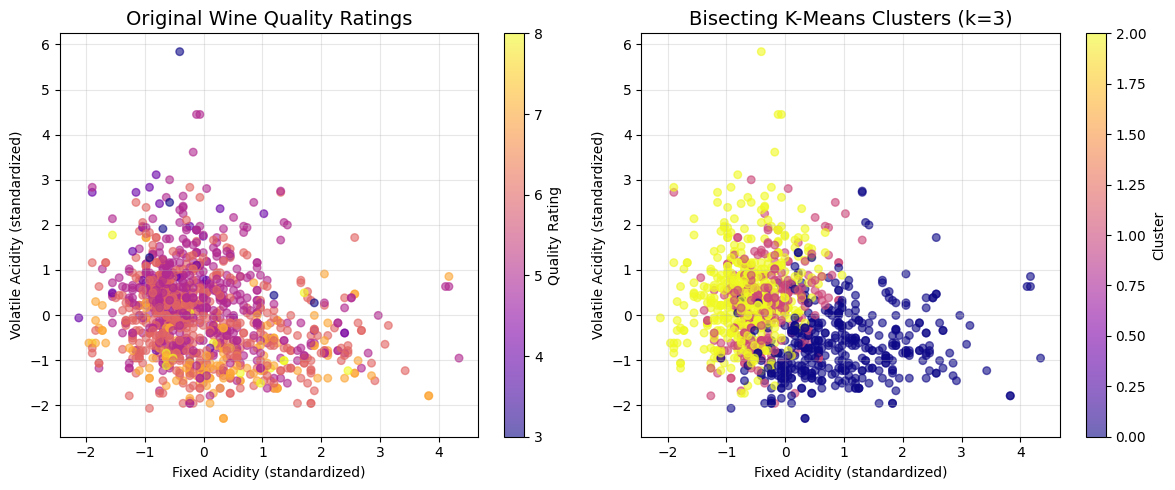

BISECTING K-MEANS CLUSTERING ANALYSIS

Clustering Quality Metrics:
  Final SSE: 9290.1
  SSE with iter=1: 9354.4
  SSE with iter=5: 9290.1 ← SELECTED
  SSE with iter=10: 9290.1

Cluster Results:
  Cluster 0:  406 samples (35.5%) | Avg quality: 5.93
  Cluster 1:  277 samples (24.2%) | Avg quality: 5.37
  Cluster 2:  460 samples (40.2%) | Avg quality: 5.59

Algorithm Performance:
  Quality separation achieved: 0.56 points
  Cluster balance: 277-460 samples per cluster
  SSE improvement over iter=1: 0.7%


In [18]:
def test_wine_clustering():
    data = np.genfromtxt("datasets/your_datasets/WineQT.csv", delimiter=",", skip_header=1)
    X = data[:, :-2]
    true_quality = data[:, -2].astype(int)
    
    X_std = (X - X.mean(axis=0)) / X.std(axis=0)
    
    k = 3
    iterations = [1, 5, 10]
    results = {}
    
    for iter in iterations:        
        labels = bkmeans(X_std, k, iter=iter)
        
        sse = calculate_sse(X_std, labels)
        cluster_sizes = np.bincount(labels)
        
        results[iter] = {'labels': labels, 'sse': sse, 'cluster_sizes': cluster_sizes}
        
    best_iter = min(results.keys(), key=lambda x: results[x]['sse'])
    best_labels = results[best_iter]['labels']
    
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.scatter(X_std[:, 0], X_std[:, 1], c=true_quality, cmap='plasma', s=30, alpha=0.6)
    plt.title('Original Wine Quality Ratings', fontsize=14)
    plt.xlabel('Fixed Acidity (standardized)')
    plt.ylabel('Volatile Acidity (standardized)')
    plt.colorbar(label='Quality Rating')
    plt.grid(True, alpha=0.3)
    
    plt.subplot(1, 2, 2)
    plt.scatter(X_std[:, 0], X_std[:, 1], c=best_labels, cmap='plasma', s=30, alpha=0.6)
    plt.title(f'Bisecting K-Means Clusters (k={k})', fontsize=14)
    plt.xlabel('Fixed Acidity (standardized)')
    plt.ylabel('Volatile Acidity (standardized)')
    plt.colorbar(label='Cluster')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print("="*60)
    print("BISECTING K-MEANS CLUSTERING ANALYSIS")
    print("="*60)
    
    print(f"\nClustering Quality Metrics:")
    print(f"  Final SSE: {results[best_iter]['sse']:.1f}")
    for iter_val in iterations:
        sse = results[iter_val]['sse']
        if iter_val == best_iter:
            print(f"  SSE with iter={iter_val}: {sse:.1f} ← SELECTED")
        else:
            print(f"  SSE with iter={iter_val}: {sse:.1f}")
    
    print(f"\nCluster Results:")
    for i, size in enumerate(results[best_iter]['cluster_sizes']):
        percentage = (size / X.shape[0]) * 100
        cluster_mask = best_labels == i
        cluster_qualities = true_quality[cluster_mask]
        avg_quality = cluster_qualities.mean()
        print(f"  Cluster {i}: {size:4d} samples ({percentage:4.1f}%) | Avg quality: {avg_quality:.2f}")
    
    print(f"\nAlgorithm Performance:")
    quality_range = max([true_quality[best_labels == i].mean() for i in range(k)]) - \
               min([true_quality[best_labels == i].mean() for i in range(k)])
    print(f"  Quality separation achieved: {quality_range:.2f} points")
    print(f"  Cluster balance: {min(results[best_iter]['cluster_sizes'])}-{max(results[best_iter]['cluster_sizes'])} samples per cluster")

    improvement = ((results[1]['sse'] - results[best_iter]['sse']) / results[1]['sse']) * 100
    print(f"  SSE improvement over iter=1: {improvement:.1f}%")
    
    return best_labels

if __name__ == "__main__":
    result = test_wine_clustering()

## Lecture 9 - Dimensionality Reduction 

### Task 1 (mandatory)

In this exercise you will visualize and explore the results of the previous exercise in a simple manner, using scatterplots.
This will be a relatively open-ended task; you will choose three data sets and explore them with the new technique you built for yourself. 

These could be data sets you already used in previous assignments, or you could download some
new data. The only restrictions are that (a) the data sets must be multidimensional (i.e., more than 4 features), (b) they must have labels, and (c) they must have at least 1000 data points.

These are some examples of interesting places to obtain new data sets:

* http://archive.ics.uci.edu/ml/index.php
* https://www.openml.org/search?type=data
* https://www.kaggle.com/datasets

Be careful, however, with the size of the data set you choose. Python can get quite slow with too much data, and the scatterplots will also be very crowded, so go for smaller data sets this time.

**Important**: Download the datasets and put them under the folder *datasets* so that we can run your code.

  Samples: 1143, Features: 12
  Explained variance with 2 components: 0.43
  Components needed for 80% variance: 6

  Samples: 1030, Features: 8
  Explained variance with 2 components: 0.46
  Components needed for 80% variance: 5

  Samples: 5875, Features: 21
  Explained variance with 2 components: 0.62
  Components needed for 80% variance: 5



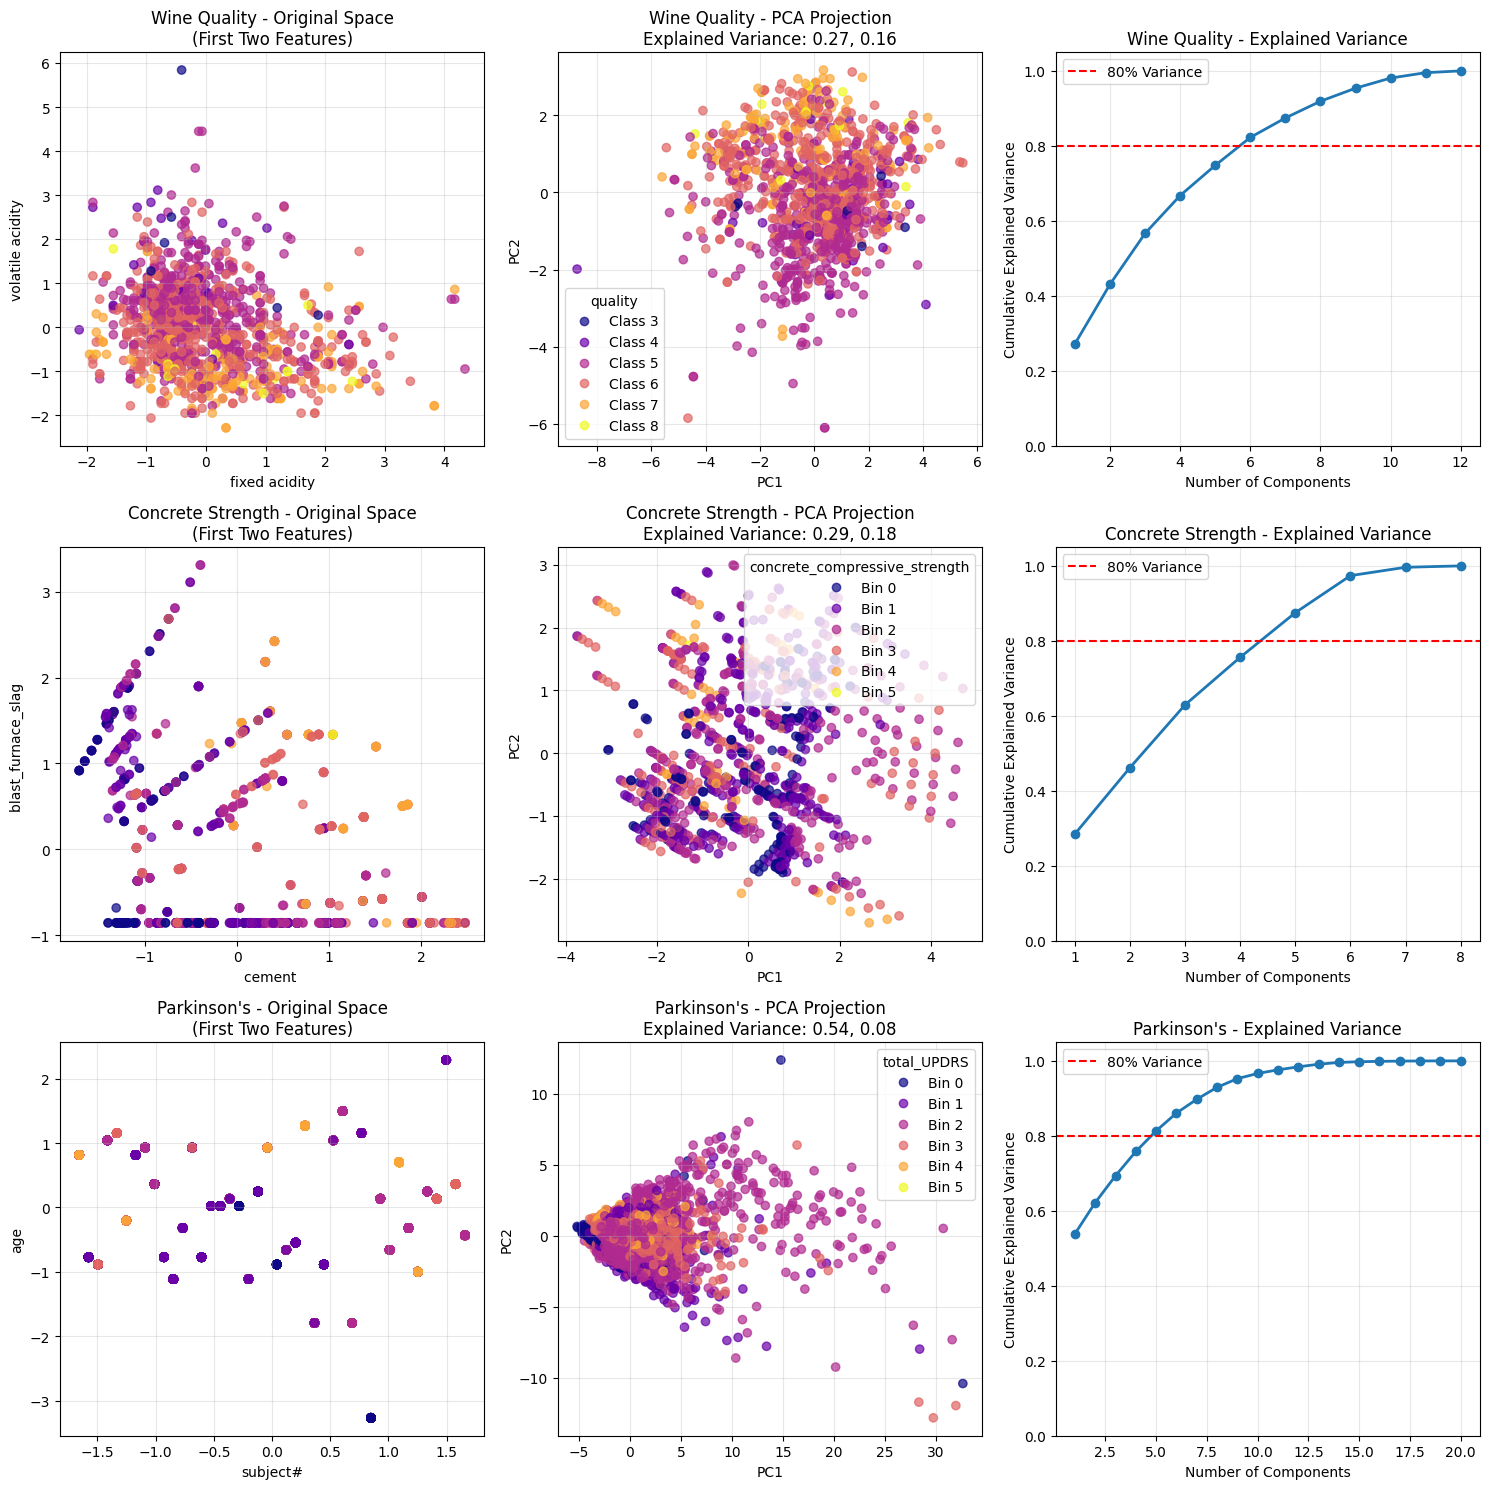

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def pca(X, n_components=2):
    X_centered = X - np.mean(X, axis=0)
    
    n_samples = X_centered.shape[0]
    cov_matrix = np.dot(X_centered.T, X_centered) / (n_samples - 1)

    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
    
    idx = eigenvalues.argsort()[::-1]
    eigenvalues = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]
    
    components = eigenvectors[:, :n_components]
    explained_variance = eigenvalues[:n_components] / np.sum(eigenvalues)
    
    X_reduces = np.dot(X_centered, components)
    
    return X_reduces, explained_variance

def load_dataset(filepath, target_column=-1, delimiter=None):
    with open(filepath, 'r') as f:
        header_line = f.readline().strip()
    
    if delimiter is None:
        if ',' in header_line:
            delimiter = ','
        elif '\t' in header_line:
            delimiter = '\t'
        else:
            delimiter = ','
    
    header = header_line.split(delimiter)
    
    data = np.genfromtxt(filepath, delimiter=delimiter, skip_header=1)
    
    if target_column < 0:
        target_column = data.shape[1] + target_column
    
    X = np.delete(data, target_column, axis=1)
    y = data[:, target_column]
    
    feature_names = header.copy()
    feature_names.pop(target_column)
    
    return X, y, feature_names, header[target_column]

def visualize_datasets():
    dataset_paths = {
        'Wine Quality': ('datasets/your_datasets/WineQT.csv', -2),
        'Concrete Strength': ('datasets/your_datasets/concrete_data.csv', -1),
        'Parkinson\'s': ('datasets/your_datasets/telemonitoring_parkinsons_updrs.data.csv', 5)
    }
    
    fig = plt.figure(figsize=(15, 5 * len(dataset_paths)))
    row = 0
    
    for name, (path, target_col) in dataset_paths.items():
        X, y, feature_names, target_name = load_dataset(path, target_column=target_col)
        
        if len(np.unique(y)) > 10:
            bins = np.linspace(np.min(y), np.max(y), 6)
            y_discrete = np.digitize(y, bins) - 1
        else:
            y_discrete = y.astype(int)
        
        X_std = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
        
        X_pca, explained_variance = pca(X_std)
        
        row += 1
        
        ax1 = fig.add_subplot(len(dataset_paths), 3, (row-1)*3+1)
        scatter = ax1.scatter(X_std[:, 0], X_std[:, 1], c=y_discrete, cmap='plasma', alpha=0.7)
        ax1.set_title(f'{name} - Original Space\n(First Two Features)', fontsize=12)
        ax1.set_xlabel(feature_names[0])
        ax1.set_ylabel(feature_names[1])
        ax1.grid(True, alpha=0.3)
        
        ax2 = fig.add_subplot(len(dataset_paths), 3, (row-1)*3+2)
        scatter = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=y_discrete, cmap='plasma', alpha=0.7)
        ax2.set_title(f'{name} - PCA Projection\nExplained Variance: {explained_variance[0]:.2f}, {explained_variance[1]:.2f}', fontsize=12)
        ax2.set_xlabel('PC1')
        ax2.set_ylabel('PC2')
        ax2.grid(True, alpha=0.3)
        
        if len(np.unique(y_discrete)) <= 10:
            handles, labels = scatter.legend_elements()
            if len(np.unique(y)) <= 10:
                ax2.legend(handles, [f'Class {int(i)}' for i in np.unique(y_discrete)], 
                          title=target_name, loc="best")
            else:
                ax2.legend(handles, [f'Bin {int(i)}' for i in np.unique(y_discrete)], 
                          title=target_name, loc="best")
        
        ax3 = fig.add_subplot(len(dataset_paths), 3, (row-1)*3+3)
        
        _, all_explained_variance = pca(X_std, n_components=min(20, X.shape[1]))
        cumulative_variance = np.cumsum(all_explained_variance)
        
        ax3.plot(range(1, len(cumulative_variance)+1), cumulative_variance, 'o-', linewidth=2)
        ax3.axhline(y=0.8, color='r', linestyle='--', label='80% Variance')
        ax3.set_title(f'{name} - Explained Variance', fontsize=12)
        ax3.set_xlabel('Number of Components')
        ax3.set_ylabel('Cumulative Explained Variance')
        ax3.set_ylim([0, 1.05])
        ax3.grid(True, alpha=0.3)
        ax3.legend()
        
        print(f"  Samples: {X.shape[0]}, Features: {X.shape[1]}")
        print(f"  Explained variance with 2 components: {np.sum(explained_variance):.2f}")
        if np.any(cumulative_variance >= 0.8):
            num_components_80pct = np.argmax(cumulative_variance >= 0.8) + 1
            print(f"  Components needed for 80% variance: {num_components_80pct}")
        else:
            print(f"  More than {len(cumulative_variance)} components needed for 80% variance")
        print()
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualize_datasets()

### Task 2 (non-mandatory) - Comparison of DR Techniques

Generate a scatterplot matrix comparing the results of three DR techniques: PCA, MDS, and t-SNE, for each data set chosen in the previous exercise. 
The resulting visualization should be a 3 × 3 matrix where each cell is a scatterplot of a DR technique applied to a data set. 
Color the points by their target variables (i.e., class/labels) using a qualitative colormap.

Then answer this shortly (in a couple of paragraphs): 
- In your opinion, which technique performed the best for each data set, regarding the separation of the classes? 
- How are the classes in the data sets separated? 
- Are some classes easier to separate than others?

---

For MSE I used Sammon's stress from the lecture slides and for the t-SNE I used this website as a reference https://towardsdatascience.com/understanding-t-sne-by-implementing-2baf3a987ab3/#:~:text=Introduction,data%20as%20much%20as%20possible.

Due to the limitations of my computer for visualisation I used a subset of the original data.

---

Best Technique for Each Dataset:
- For Wine Quality t-SNE worked the best because it showed clear cluster separation with distinct groups that matched the different quality classes. MDS was okay, showing some separation, but PCA mostly had overlapping clusters. 
- For Concrete Strength PCA was the best since it showed a clear linear gradient.
- For Parkinson's t-SNE was the best again, as it created clear clusters that separated the different progression stages. MDS showed some structure, but PCA had a lot of overlap.

The datasets show different ways their data is separated based on their structure:
- For Concrete Strength, the separation is linear, this is why PCA works well here.

- For Wine Quality and Parkinson's, the separation is cluster-based. This is why t-SNE, which is good at finding non-linear patterns, works better for these datasets. 

Some classes are easier to separate than others. In Wine Quality, wines with very high or very low ratings form clear, tight clusters, but middle-quality wines overlap more. In Concrete Strength the datas nature makes adjacent classes moderately separable along the strength scale. In Parkinson's data, some disease stages form tighter, more distinct clusters, showing that certain stages have more unique patterns in their features.

In [6]:
def euclidean_distance_matrix(X):
    n_samples = X.shape[0]
    distances = np.zeros((n_samples, n_samples))
    
    for i in range(n_samples):
        for j in range(i + 1, n_samples):
            dist = np.sqrt(np.sum((X[i] - X[j])**2))
            distances[i, j] = distances[j, i] = dist
            
    return distances

def mds(X, n_components=2, max_iter=100, learning_rate=0.01):
    n_samples = X.shape[0]

    if n_samples > 500:
        indices = np.random.choice(n_samples, 500, replace=False)
        X_subset = X[indices]
        n_samples = 500
    else:
        X_subset = X
        indices = np.arange(n_samples)

    delta = euclidean_distance_matrix(X)
    delta_safe = np.where(delta == 0, 1e-8, delta)  

    c = np.sum(delta) / 2
    
    Y, _ = pca(X_subset, n_components)

    for iteration in range(max_iter):
        dist = euclidean_distance_matrix(Y)

        dist_safe= np.where(dist == 0, 1e-8, dist)

        stress = 0.0

        for i in range(n_samples):
            for j in range(i+1, n_samples):
                if delta[i, j] > 0:
                    stress += (delta[i, j] - dist[i, j])**2 / delta_safe[i, j]
        stress /= c

        if iteration % 50 == 0:
            if stress < 1e-6:
                break          

        grad = np.zeros_like(Y)
        for i in range(n_samples):
            grad_i = np.zeros(n_components)
            for j in range(n_samples):
                if i != j:
                    factor = (delta[i, j] - dist[i, j]) / (delta_safe[i, j] * dist_safe[i, j])
                    grad_i += factor * (Y[i] - Y[j])
            grad[i] = grad_i
            
        grad *= (-2 / c)
        
        Y -= learning_rate * grad
        
    return Y, indices

def compute_sigma_for_perplexity(distances_row, target_perplexity=30.0, tolerance=1e-8, max_iter=100):
    low_bound, upp_bound = 1e-20, 1000.0
    
    for _ in range(max_iter):
        sigma = (upp_bound + low_bound) / 2.0
        
        probs = np.exp(-distances_row / (2 * sigma**2))
        probs += 1e-8
        probs = probs / np.sum(probs)
        
        entropy = -np.sum(probs * np.log2(probs + 1e-8))
        perplexity = 2 ** entropy
        
        if abs(perplexity - target_perplexity) <= tolerance:
            return sigma
        
        if perplexity > target_perplexity:
            upp_bound = sigma
        else:
            low_bound = sigma
    
    return sigma

def tsne(X, n_components=2, perplexity=30, max_iter=100, learning_rate=200.0):
    n_samples = X.shape[0]
    
    if n_samples > 500:
        np.random.seed(65)
        indices = np.random.choice(n_samples, 500, replace=False)
        X_subset = X[indices]
        n_samples = 500
    else:
        X_subset = X
        indices = np.arange(n_samples)
    
    perplexity = min(perplexity, n_samples // 3)
    if perplexity >= n_samples:
        perplexity = max(1, n_samples // 4)
    
    distances_sq = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            if i != j:
                distances_sq[i, j] = np.sum((X_subset[i] - X_subset[j])**2)
    
    sigmas = np.zeros(n_samples)
    for i in range(n_samples):
        dist_row = distances_sq[i].copy()
        dist_row[i] = np.inf
        sigmas[i] = compute_sigma_for_perplexity(dist_row, perplexity)
    
    P_conditional = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        sigma = sigmas[i]
        probs = np.exp(-distances_sq[i] / (2 * sigma**2))
        probs[i] = 0
        probs += 1e-8
        P_conditional[i] = probs / np.sum(probs)
    
    P = (P_conditional + P_conditional.T) / (2 * n_samples)
    P = np.maximum(P, 1e-12)
    
    np.random.seed(42)
    Y = np.random.normal(0, 1e-4, (n_samples, n_components))
    Y_previous = Y.copy()
    
    for iteration in range(max_iter):
        sum_Y = np.sum(Y**2, axis=1)
        distances_Y = sum_Y[:, None] + sum_Y[None, :] - 2 * np.dot(Y, Y.T)
        
        Q_numerator = 1 / (1 + distances_Y)
        np.fill_diagonal(Q_numerator, 0)
        Q = Q_numerator / np.sum(Q_numerator)
        Q = np.maximum(Q, 1e-12)
        
        probability_difference = P - Q
        gradient = np.zeros_like(Y)
        
        Y_differences = Y[:, None, :] - Y[None, :, :]
        gradient_factors = (probability_difference[:, :, None] * Q_numerator[:, :, None] * Y_differences)
        gradient = 4 * np.sum(gradient_factors, axis=1)
        
        momentum_factor = 0.5 if iteration < 250 else 0.8
        Y_new = Y - learning_rate * gradient + momentum_factor * (Y - Y_previous)
        Y_previous = Y.copy()
        Y = Y_new
        
        Y = Y - np.mean(Y, axis=0)
    
    return Y, indices

def visualize_datasets():
    dataset_paths = {
        'Wine Quality': ('datasets/your_datasets/WineQT.csv', -2),
        'Concrete Strength': ('datasets/your_datasets/concrete_data.csv', -1),
        'Parkinson\'s': ('datasets/your_datasets/telemonitoring_parkinsons_updrs.data.csv', 5)
    }
    
    fig = plt.figure(figsize=(18, 6 * len(dataset_paths)))
    row = 0
    
    for name, (path, target_col) in dataset_paths.items():
        X, y, feature_names, target_name = load_dataset(path, target_column=target_col)
        
        if len(np.unique(y)) > 10:
            bins = np.linspace(np.min(y), np.max(y), 6)
            y_discrete = np.digitize(y, bins) - 1
        else:
            y_discrete = y.astype(int)
        
        X_std = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
        
        print(f"{name} Dataset:")
        print(f"  Samples: {X.shape[0]}, Features: {X.shape[1]}")
        print(f"  Target classes: {len(np.unique(y_discrete))}")
        
        X_pca, explained_variance = pca(X_std)
        print(f"  PCA explained variance: {explained_variance[0]:.3f}, {explained_variance[1]:.3f}")
        
        X_mds, mds_indices = mds(X_std)
        print(f"  MDS processed {len(mds_indices)} samples")
        
        X_tsne, tsne_indices = tsne(X_std)
        print(f"  t-SNE processed {len(tsne_indices)} samples")
        print()
        
        row += 1
        
        ax1 = fig.add_subplot(len(dataset_paths), 3, (row-1)*3+1)
        scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=y_discrete, cmap='viridis', alpha=0.7, s=15)
        ax1.set_title(f'{name} - PCA\nExplained Variance: {explained_variance[0]:.3f}, {explained_variance[1]:.3f}', fontsize=12)
        ax1.set_xlabel('PC1')
        ax1.set_ylabel('PC2')
        ax1.grid(True, alpha=0.3)
        
        ax2 = fig.add_subplot(len(dataset_paths), 3, (row-1)*3+2)
        if len(mds_indices) == len(y_discrete):
            y_mds = y_discrete
        else:
            y_mds = y_discrete[mds_indices]
        scatter2 = ax2.scatter(X_mds[:, 0], X_mds[:, 1], c=y_mds, cmap='viridis', alpha=0.7, s=15)
        ax2.set_title(f'{name} - Sammon MDS\nSamples: {len(mds_indices)}', fontsize=12)
        ax2.set_xlabel('MDS1')
        ax2.set_ylabel('MDS2')
        ax2.grid(True, alpha=0.3)
        
        ax3 = fig.add_subplot(len(dataset_paths), 3, (row-1)*3+3)
        if len(tsne_indices) == len(y_discrete):
            y_tsne = y_discrete
        else:
            y_tsne = y_discrete[tsne_indices]
        scatter3 = ax3.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_tsne, cmap='viridis', alpha=0.7, s=15)
        ax3.set_title(f'{name} - t-SNE\nSamples: {len(tsne_indices)}', fontsize=12)
        ax3.set_xlabel('t-SNE1')
        ax3.set_ylabel('t-SNE2')
        ax3.grid(True, alpha=0.3)
        
        if len(np.unique(y_discrete)) <= 10:
            handles, labels = scatter1.legend_elements()
            if len(np.unique(y)) <= 10:
                legend_labels = [f'Class {int(i)}' for i in np.unique(y_discrete)]
            else:
                legend_labels = [f'Bin {int(i)}' for i in np.unique(y_discrete)]
            
            ax1.legend(handles, legend_labels, title=target_name, loc="best", fontsize=8)
            ax2.legend(handles, legend_labels, title=target_name, loc="best", fontsize=8)
            ax3.legend(handles, legend_labels, title=target_name, loc="best", fontsize=8)
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualize_datasets()

Wine Quality Dataset:
  Samples: 1143, Features: 12
  Target classes: 6
  PCA explained variance: 0.272, 0.159


### Task 3 (non-mandatory): Comparison of Clustering Techniques

Choose one of the DR techniques from the previous exercise and generate a similar scatterplot matrix to compare the results of Bisecting k-Means with classic k-Means and hierarchical clustering for each data set. 
The resulting visualization should be a 3 × 3 matrix where each cell is a scatterplot of the chosen DR technique applied to a data set, with the colors of the points showing the clusters using a qualitative colormap (see, e.g., https://matplotlib.org/tutorials/colors/colormaps.html).

Then answer this shortly (in a couple of paragraphs): 
- In your opinion, which clustering technique performed the best for each data set? 
- How are the clusters in the data sets separated? 
- Are some clusters easier to separate than others?